## Análise exploratória

### 0. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.cloud import bigquery
from scipy.spatial import cKDTree
from scipy.stats import chi2_contingency, rankdata

### 1. Parâmetros

In [2]:
par_source_project = "tech-challenge-fase-2-505123"
par_gold = f"{par_source_project}.gold"
par_source_gold_fato_aluno = f"{par_gold}.fato_aluno"
par_source_gold_fato_meta = f"{par_gold}.fato_meta"
par_source_gold_fato_indicador_municipio = f"{par_gold}.fato_indicador_municipio"
par_source_gold_fato_indicador_uf = f"{par_gold}.fato_indicador_uf"
par_source_gold_fato_resultados = f"{par_gold}.fato_resultados"
par_source_gold_dim_municipio = f"{par_gold}.dim_municipio"
par_source_gold_dim_uf = f"{par_gold}.dim_uf"
par_source_gold_dim_rede = f"{par_gold}.dim_rede"

par_bd = "basedosdados"
par_corte = 743
par_rede_estadual = "2"
par_rede_municipal = "3"
par_min_alunos = 30
par_seed = 42
par_faixas_porte = [0, 30, 100, 300, 1000, np.inf]
par_rotulos_porte = ["<30", "30-99", "100-299", "300-999", "1000+"]
par_cores = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]

client = bigquery.Client(project=par_source_project)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "axes.axisbelow": True,
                     "axes.titlelocation": "left", "axes.titlesize": 11, "font.size": 9})
pd.set_option("display.max_columns", 50, "display.float_format", "{:,.2f}".format)

### 2. Funções Auxiliares

In [3]:
def ler_tabela(tabela: str, colunas: list | None = None) -> pd.DataFrame:
    t = client.get_table(tabela)
    if t.table_type == "VIEW":
        return client.query(f"select {', '.join(colunas) if colunas else '*'} from `{tabela}`").to_dataframe()
    campos = [c for c in t.schema if c.name in colunas] if colunas else None
    return client.list_rows(t, selected_fields=campos).to_dataframe()


def para_numero(s):
    return pd.to_numeric(s, errors="coerce")


def divisao_segura(a, b):
    return a / b.where(b != 0)


def amostra_hash(chave, n=5):
    return pd.util.hash_pandas_object(pd.Series(chave), index=False).to_numpy() % n == 0


def taxa_ponderada(df, grupos, numerador, peso, nome="taxa"):
    g = df.groupby(grupos, observed=True)[[numerador, peso]].sum()
    return (100 * g[numerador] / g[peso]).rename(nome).reset_index()


def icc_binario(df, grupo, n, y):
    g = df.groupby(grupo, observed=True)[[n, y]].sum()
    g = g[g[n] > 0]
    N, k, p = g[n].sum(), len(g), g[y].sum() / g[n].sum()
    pi = g[y] / g[n]
    msb = (g[n] * (pi - p) ** 2).sum() / (k - 1)
    msw = (g[n] * pi * (1 - pi)).sum() / (N - k)
    n0 = (N - (g[n] ** 2).sum() / N) / (k - 1)
    return (msb - msw) / (msb + (n0 - 1) * msw)


def auc(y, score):
    y = np.asarray(y, dtype=bool)
    r = rankdata(score)
    n1, n0 = y.sum(), (~y).sum()
    return (r[y].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)


def moran_i(valores, coords, k=8):
    z = np.asarray(valores) - np.mean(valores)
    _, viz = cKDTree(coords).query(coords, k=k + 1)
    return (z * z[viz[:, 1:]].mean(axis=1)).sum() / (z ** 2).sum()


def v_cramer(a, b):
    t = pd.crosstab(a, b)
    return np.sqrt(chi2_contingency(t)[0] / (t.values.sum() * (min(t.shape) - 1)))


def r2_ols(X, y):
    X = np.column_stack([np.ones(len(X)), np.asarray(X, dtype=float)])
    y = np.asarray(y, dtype=float)
    res = y - X @ np.linalg.lstsq(X, y, rcond=None)[0]
    return 1 - (res ** 2).sum() / ((y - y.mean()) ** 2).sum()


def correlacao_parcial(df, x, y, controles):
    d = df[[x, y] + controles].dropna().rank()
    C = np.column_stack([np.ones(len(d)), d[controles]])
    res = lambda v: v - C @ np.linalg.lstsq(C, v, rcond=None)[0]
    return np.corrcoef(res(d[x].values), res(d[y].values))[0, 1]


def resumo_colunas(df):
    num = df.select_dtypes("number")
    return pd.DataFrame({"tipo": df.dtypes.astype(str), "pct_nulos": df.isna().mean() * 100,
                         "unicos": df.nunique(), "assimetria": num.skew(),
                         "pct_outliers_iqr": ((num < num.quantile(.25) - 1.5 * (num.quantile(.75) - num.quantile(.25)))
                                              | (num > num.quantile(.75) + 1.5 * (num.quantile(.75) - num.quantile(.25)))).mean() * 100})


def plot_barras(df, x, y, hue=None, titulo="", xlabel=None, ylabel=None, referencia=None, figsize=None, fmt="%.1f"):
    tab = df.pivot(index=x, columns=hue, values=y) if hue else df.set_index(x)[[y]]
    altura = max(2.4, .28 * len(tab) * (tab.shape[1] if hue else 1) + 1)
    ax = tab[::-1].plot.barh(figsize=figsize or (8, altura), color=par_cores[:tab.shape[1]], width=.8,
                             edgecolor="white", linewidth=1.5, legend=bool(hue))
    if referencia is not None:
        ax.axvline(referencia, color="#52514e", linestyle="--", linewidth=1)
    if not hue:
        ax.bar_label(ax.containers[0], fmt=fmt, padding=3, fontsize=8)
    ax.grid(axis="y", visible=False)
    ax.set(title=titulo, xlabel=xlabel or y, ylabel=ylabel or "")
    plt.tight_layout()
    plt.show()


def plot_linhas(df, x, y, hue=None, titulo="", xlabel=None, ylabel=None, referencia=None, figsize=(8, 3.6)):
    fig, ax = plt.subplots(figsize=figsize)
    grupos = df.groupby(hue, observed=True) if hue else [(y, df)]
    for cor, (nome, d) in zip(par_cores, grupos):
        ax.plot(d[x], d[y], color=cor, linewidth=2, marker="o", markersize=5, label=nome)
    if referencia is not None:
        ax.axvline(referencia, color="#52514e", linestyle="--", linewidth=1)
    if hue:
        ax.legend(frameon=False)
    ax.set(title=titulo, xlabel=xlabel or x, ylabel=ylabel or y)
    plt.tight_layout()
    plt.show()


def plot_hist(valores, bins=40, titulo="", xlabel="", referencia=None, figsize=(8, 3.2)):
    fig, ax = plt.subplots(figsize=figsize)
    ax.hist(pd.Series(valores).dropna(), bins=bins, color=par_cores[0], edgecolor="white", linewidth=.8)
    if referencia is not None:
        ax.axvline(referencia, color="#52514e", linestyle="--", linewidth=1)
    ax.set(title=titulo, xlabel=xlabel, ylabel="frequência")
    plt.tight_layout()
    plt.show()


def plot_dispersao(df, x, y, hue=None, titulo="", diagonal=False, amostra=4000, figsize=(6.5, 5)):
    d = df[[c for c in [x, y, hue] if c]].dropna()
    d = d.sample(min(amostra, len(d)), random_state=par_seed)
    fig, ax = plt.subplots(figsize=figsize)
    grupos = d.groupby(hue, observed=True) if hue else [(y, d)]
    for cor, (nome, g) in zip(par_cores, grupos):
        ax.scatter(g[x], g[y], s=10, alpha=.45, color=cor, linewidths=0, label=nome)
    if diagonal:
        lim = [d[[x, y]].min().min(), d[[x, y]].max().max()]
        ax.plot(lim, lim, color="#52514e", linestyle="--", linewidth=1)
    if hue:
        ax.legend(frameon=False, markerscale=2)
    ax.set(title=titulo, xlabel=x, ylabel=y)
    plt.tight_layout()
    plt.show()


def plot_heatmap(tab, titulo="", divergente=False, fmt=".2f", figsize=None):
    from matplotlib.colors import LinearSegmentedColormap
    cores = ["#e34948", "#f0efec", "#2a78d6"] if divergente else ["#f0efec", "#2a78d6"]
    limites = {"vmin": -1, "vmax": 1} if divergente else {}
    fig, ax = plt.subplots(figsize=figsize or (max(6, .6 * tab.shape[1] + 2), max(3, .38 * tab.shape[0] + 1)))
    im = ax.imshow(tab.astype(float), cmap=LinearSegmentedColormap.from_list("c", cores), aspect="auto", **limites)
    ax.set_xticks(range(tab.shape[1]), tab.columns, rotation=45, ha="right")
    ax.set_yticks(range(tab.shape[0]), tab.index)
    ax.grid(False)
    if tab.size <= 225:
        for (i, j), v in np.ndenumerate(tab.astype(float).values):
            if not np.isnan(v):
                ax.text(j, i, format(v, fmt), ha="center", va="center", fontsize=7, color="#0b0b0b")
    ax.set_title(titulo)
    fig.colorbar(im, ax=ax, shrink=.8)
    plt.tight_layout()
    plt.show()

### 3. Leitura de dados

#### 3.1. Dados da camada gold

In [4]:
df_scr_meta = ler_tabela(par_source_gold_fato_meta)
df_scr_indicador_municipio = ler_tabela(par_source_gold_fato_indicador_municipio)
df_scr_indicador_uf = ler_tabela(par_source_gold_fato_indicador_uf)
df_scr_resultados = ler_tabela(par_source_gold_fato_resultados)
df_scr_municipio = ler_tabela(par_source_gold_dim_municipio)
df_scr_uf = ler_tabela(par_source_gold_dim_uf)
df_scr_rede = ler_tabela(par_source_gold_dim_rede)
df_scr_aluno = ler_tabela(par_source_gold_fato_aluno)

In [5]:
g_escola = (df_scr_aluno
            .assign(avaliado=df_scr_aluno["proficiencia"].notna(),
                    peso_alfabetizados=df_scr_aluno["peso_aluno"].where(df_scr_aluno["alfabetizado"].fillna(False), 0))
            .groupby(["ano", "id_escola", "id_municipio", "rede_id"], dropna=False))
df_scr_escola = g_escola.agg(n_total=("id_aluno", "size"), n_presentes=("presenca", "sum"), n_avaliados=("avaliado", "sum"),
                             n_alfabetizados=("alfabetizado", "sum"))
df_scr_escola["peso"] = g_escola["peso_aluno"].sum(min_count=1)
df_scr_escola["peso_alfabetizados"] = g_escola["peso_alfabetizados"].sum()
df_scr_escola = df_scr_escola.reset_index().astype({c: "Int64" for c in ["n_total", "n_presentes", "n_avaliados", "n_alfabetizados"]})

#### 3.2. Fontes externas (Base dos Dados)

##### 3.2.1. Dados socioeconômicos

In [6]:
df_scr_atlas = (ler_tabela(f"{par_bd}.mundo_onu_adh.municipio",
                           ["ano", "id_municipio", "idhm", "idhm_e", "renda_pc", "indice_gini", "prop_pobreza_criancas", "expectativa_anos_estudo"])
                .query("ano == 2010").drop(columns="ano").reset_index(drop=True))

##### 3.2.2. Dados populacionais

In [7]:
df_scr_pop = ler_tabela(f"{par_bd}.br_ibge_populacao.municipio", ["ano", "id_municipio", "populacao"]).query("ano == 2022")
df_scr_pib = ler_tabela(f"{par_bd}.br_ibge_pib.municipio", ["ano", "id_municipio", "pib"]).query("ano == 2022")
df_scr_populacao = df_scr_pop.merge(df_scr_pib, on=["ano", "id_municipio"], how="left")
df_scr_populacao["pib_per_capita"] = divisao_segura(df_scr_populacao["pib"], df_scr_populacao["populacao"])
df_scr_populacao = df_scr_populacao[["id_municipio", "populacao", "pib_per_capita"]].reset_index(drop=True)

##### 3.2.3. Censo escolar

In [8]:
par_matricula, par_turma, par_docente = [f"quantidade_{c}_fundamental_anos_iniciais" for c in ["matricula", "turma", "docente"]]
df_scr_censo_escola = ler_tabela(f"{par_bd}.br_inep_censo_escolar.escola",
                                 ["ano", "id_escola", "id_municipio", "rede", "tipo_situacao_funcionamento", "etapa_ensino_fundamental_anos_iniciais",
                                  "tipo_localizacao", "biblioteca_sala_leitura", "internet_alunos", "esgoto_rede_publica",
                                  par_matricula, par_turma, par_docente])
df_censo = df_scr_censo_escola[(df_scr_censo_escola["ano"] == 2023) & (para_numero(df_scr_censo_escola["rede"]) == 3)
                               & (para_numero(df_scr_censo_escola["tipo_situacao_funcionamento"]) == 1)
                               & (df_scr_censo_escola["etapa_ensino_fundamental_anos_iniciais"] == 1)]
df_censo = df_censo.assign(rural=(para_numero(df_censo["tipo_localizacao"]) == 2).astype(int))
df_scr_censo = df_censo.groupby("id_municipio").agg(
    escolas_anos_iniciais=("id_municipio", "size"), pct_escolas_rurais=("rural", "mean"), pct_biblioteca=("biblioteca_sala_leitura", "mean"),
    pct_internet_alunos=("internet_alunos", "mean"), pct_esgoto_rede=("esgoto_rede_publica", "mean"))
df_scr_censo[["pct_escolas_rurais", "pct_biblioteca", "pct_internet_alunos", "pct_esgoto_rede"]] *= 100
soma_censo = df_censo.groupby("id_municipio")[[par_matricula, par_turma, par_docente]].sum(min_count=1)
df_scr_censo["alunos_por_turma"] = divisao_segura(soma_censo[par_matricula], soma_censo[par_turma])
df_scr_censo["alunos_por_docente"] = divisao_segura(soma_censo[par_matricula], soma_censo[par_docente])
df_scr_censo = df_scr_censo.reset_index()

##### 3.2.4. Dados educacionais

In [9]:
par_colunas_inep = {"atu_ef_2_ano": "alunos_turma_2ano", "had_ef_2_ano": "horas_aula_2ano", "tdi_ef_anos_iniciais": "distorcao_idade_serie",
                    "taxa_aprovacao_ef_anos_iniciais": "taxa_aprovacao", "taxa_abandono_ef_anos_iniciais": "taxa_abandono",
                    "dsu_ef_anos_iniciais": "pct_docente_superior", "afd_ef_anos_iniciais_grupo_1": "pct_docente_adequado",
                    "ird_baixa_regularidade": "pct_docente_baixa_regularidade"}
df_inep = ler_tabela(f"{par_bd}.br_inep_indicadores_educacionais.municipio", ["ano", "id_municipio", "localizacao", "rede", *par_colunas_inep])
df_scr_indicadores_educ = (df_inep[(df_inep["ano"] == 2022) & (df_inep["localizacao"].str.lower() == "total") & (df_inep["rede"].str.lower() == "municipal")]
                           [["id_municipio", *par_colunas_inep]].rename(columns=par_colunas_inep).reset_index(drop=True))
df_scr_indicadores_educ[list(par_colunas_inep.values())] = df_scr_indicadores_educ[list(par_colunas_inep.values())].apply(para_numero)

In [10]:
df_fundeb = ler_tabela(f"{par_bd}.br_fnde_fundeb.indicador_municipal", ["ano", "bimestre", "id_municipio", "id_indicador", "valor_real"])
df_fundeb = df_fundeb[(df_fundeb["ano"] == 2023) & (df_fundeb["bimestre"] == 6) & df_fundeb["id_indicador"].astype(str).isin(["45", "58"])]
df_scr_fundeb = (df_fundeb.groupby(["id_municipio", df_fundeb["id_indicador"].astype(str)])["valor_real"].max().unstack()
                 .reindex(columns=["45", "58"])
                 .rename(columns={"45": "invest_aluno_fundamental", "58": "despesa_professor_aluno"})
                 .rename_axis(columns=None).reset_index())

In [11]:
df_scr_territorio = ler_tabela(f"{par_bd}.br_bd_diretorios_brasil.municipio",
                               ["id_municipio", "nome_mesorregiao", "capital_uf", "amazonia_legal", "centroide"])
df_scr_territorio[["lon", "lat"]] = df_scr_territorio["centroide"].astype(str).str.extract(r"POINT\((\S+) (\S+)\)").astype(float)
df_scr_territorio = df_scr_territorio.drop(columns="centroide")

### 4. Transformações

In [12]:
df_escola = df_scr_escola.merge(df_scr_municipio, on="id_municipio", how="left")
df_mun_aluno = (df_escola
                .groupby(["ano", "id_municipio", "rede_id", "nome_municipio", "sigla_uf", "nome_regiao"], as_index=False)
                [["n_total", "n_presentes", "n_avaliados", "n_alfabetizados", "peso", "peso_alfabetizados"]].sum())
df_mun_aluno["taxa_presenca"] = 100 * df_mun_aluno["n_presentes"] / df_mun_aluno["n_total"]
df_mun_aluno["taxa_ponderada"] = 100 * df_mun_aluno["peso_alfabetizados"] / df_mun_aluno["peso"]
df_mun_aluno["porte"] = pd.cut(df_mun_aluno["n_avaliados"], par_faixas_porte, labels=par_rotulos_porte, right=False)

In [13]:
df_municipal = df_scr_resultados[df_scr_resultados["rede_id"] == par_rede_municipal]
df_painel = (df_municipal
             .pivot(index="id_municipio", columns="ano", values="taxa_alfabetizacao")
             .rename(columns={2023: "taxa_2023", 2024: "taxa_2024"})
             .reset_index())
df_painel = df_painel.merge(
    df_municipal.loc[df_municipal["ano"] == 2024, ["id_municipio", "meta_ano", "atingiu_meta_ano", "meta_2030", "gap_ate_2030"]],
    on="id_municipio", how="left")
for ano in [2023, 2024]:
    df_painel = df_painel.merge(
        df_mun_aluno.loc[(df_mun_aluno["ano"] == ano) & (df_mun_aluno["rede_id"] == par_rede_municipal), ["id_municipio", "n_avaliados"]]
        .rename(columns={"n_avaliados": f"n_{ano}"}), on="id_municipio", how="left")
df_painel = df_painel.merge(df_scr_municipio, on="id_municipio", how="left")
df_painel["variacao"] = df_painel["taxa_2024"] - df_painel["taxa_2023"]
df_painel["atingiu_meta_ano"] = df_painel["atingiu_meta_ano"].astype("boolean")
df_painel["porte"] = pd.cut(df_painel["n_2024"], par_faixas_porte, labels=par_rotulos_porte, right=False)
df_painel.head()

,id_municipio,taxa_2023,taxa_2024,meta_ano,atingiu_meta_ano,meta_2030,gap_ate_2030,n_2023,n_2024,nome_municipio,sigla_uf,nome_uf,nome_regiao,variacao,porte
0,1100015,64.55,67.79,67.08,True,80.00,12.21,227,275,Alta Floresta D'Oeste,RO,Rondônia,Norte,3.24,100-299
1,1100023,62.30,65.62,65.22,True,80.00,14.38,1222,1066,Ariquemes,RO,Rondônia,Norte,3.32,1000+
2,1100031,69.10,75.88,70.85,True,80.00,4.12,76,75,Cabixi,RO,Rondônia,Norte,6.78,30-99
3,1100049,62.51,65.81,65.39,True,80.00,14.19,613,796,Cacoal,RO,Rondônia,Norte,3.30,300-999
4,1100056,58.53,66.81,62.09,True,80.00,13.19,222,244,Cerejeiras,RO,Rondônia,Norte,8.28,100-299


In [14]:
par_externas = {"Atlas 2010": df_scr_atlas, "IBGE 2022": df_scr_populacao, "Censo Escolar 2023": df_scr_censo,
                "Indicadores INEP 2022": df_scr_indicadores_educ, "Fundeb/SIOPE 2023": df_scr_fundeb}
df_base = df_painel.copy()
for fonte in par_externas.values():
    df_base = df_base.merge(fonte, on="id_municipio", how="left")
df_base = df_base.merge(df_scr_territorio, on="id_municipio", how="left")
par_variaveis = [c for fonte in par_externas.values() for c in fonte.columns if c != "id_municipio"]
df_base[par_variaveis] = df_base[par_variaveis].astype(float)
df_base.shape

(5500, 45)

### 5. Perguntas necessárias para a modelagem

#### Qual é a população-alvo: todos os alunos ou somente os avaliados?

In [15]:
df_p1 = df_escola.groupby("ano")[["n_total", "n_presentes", "n_avaliados", "n_alfabetizados"]].sum()
df_p1["pct_nao_avaliados"] = 100 * (1 - df_p1["n_avaliados"] / df_p1["n_total"])
df_p1["taxa_todos"] = 100 * df_p1["n_alfabetizados"] / df_p1["n_total"]
df_p1["taxa_avaliados"] = 100 * df_p1["n_alfabetizados"] / df_p1["n_avaliados"]
df_p1

,n_total,n_presentes,n_avaliados,n_alfabetizados,pct_nao_avaliados,taxa_todos,taxa_avaliados
ano,,,,,,,
2023,1747439,1503058,1502809,877427,14.00,50.21,58.39
2024,2120560,1852788,1851852,1107119,12.67,52.21,59.78


**Conclusão:** Vamos utilizar somente os avaliados. Os não avaliados (14,0% em 2023 e 12,7% em 2024) não têm alvo observado, e a taxa oficial também os exclui.

#### A ausência na prova é aleatória ou se concentra?

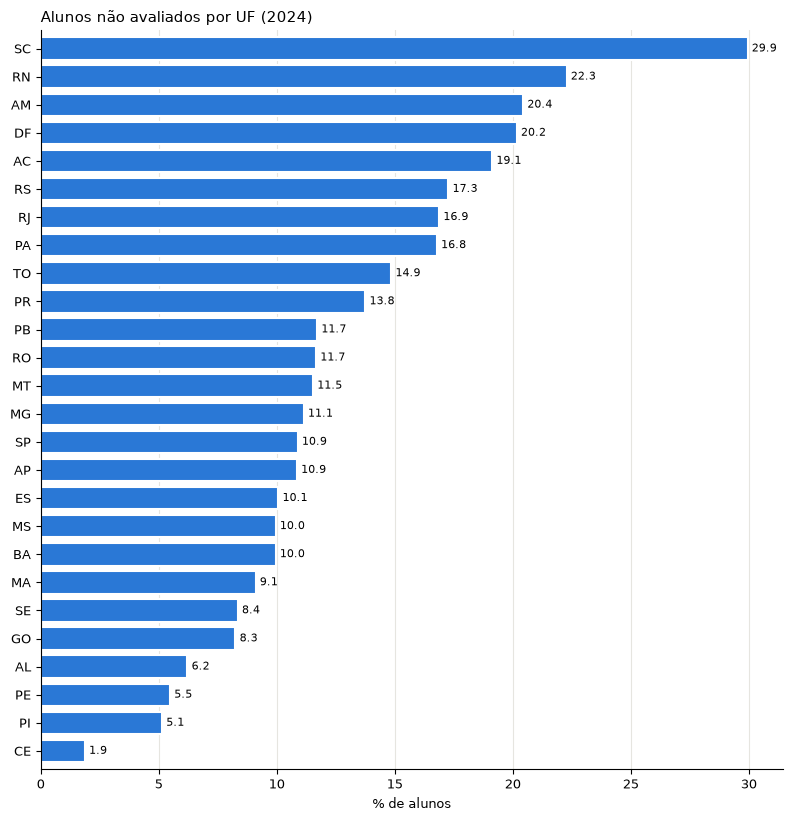

In [16]:
df_p2_uf = df_mun_aluno[df_mun_aluno["ano"] == 2024].groupby("sigla_uf", as_index=False)[["n_total", "n_avaliados"]].sum()
df_p2_uf["pct_nao_avaliados"] = 100 * (1 - df_p2_uf["n_avaliados"] / df_p2_uf["n_total"])
plot_barras(df_p2_uf.sort_values("pct_nao_avaliados", ascending=False), "sigla_uf", "pct_nao_avaliados",
            titulo="Alunos não avaliados por UF (2024)", xlabel="% de alunos")

In [17]:
df_p2 = df_escola[df_escola["n_total"] >= par_min_alunos].copy()
df_p2["pct_nao_avaliados"] = 100 * (1 - df_p2["n_avaliados"] / df_p2["n_total"])
df_p2["taxa_avaliados"] = 100 * df_p2["n_alfabetizados"] / df_p2["n_avaliados"]
df_p2["faixa_ausencia"] = pd.cut(df_p2["pct_nao_avaliados"], [-1, 5, 10, 20, 40, 100])
df_p2.groupby("faixa_ausencia", observed=True).agg(escolas=("id_escola", "size"), taxa_media=("taxa_avaliados", "mean"))

,escolas,taxa_media
faixa_ausencia,,
"(-1, 5]",9387,66.56
"(5, 10]",11991,61.77
"(10, 20]",17093,56.95
"(20, 40]",7956,50.29
"(40, 100]",967,46.74


**Conclusão:** Não é aleatória. A ausência vai de 1,9% (CE) a 29,6% (SC), e escolas com mais ausência têm taxas menores (66,6% com até 5% de ausência; 46,7% acima de 40%). Excluir esses alunos pode superestimar a taxa nas áreas mais afetadas.

#### Quanto da variação do alvo fica entre regiões, UFs, municípios e escolas?

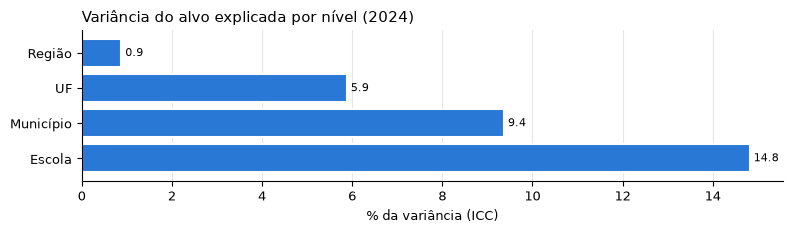

In [18]:
df_p3_base = df_escola[df_escola["ano"] == 2024]
df_p3 = pd.DataFrame({"nivel": ["Região", "UF", "Município", "Escola"],
                      "icc": [100 * icc_binario(df_p3_base, g, "n_avaliados", "n_alfabetizados")
                              for g in ["nome_regiao", "sigla_uf", "id_municipio", "id_escola"]]})
plot_barras(df_p3, "nivel", "icc", titulo="Variância do alvo explicada por nível (2024)", xlabel="% da variância (ICC)")

**Conclusão:** A maior parte não é territorial: região explica 0,9%, UF 5,9%, município 9,4% e escola 14,8%. Cerca de 85% da variância está dentro da escola, sem variável individual que a explique, o que limita o modelo de aluno.

#### Cobertura das fontes externas

In [19]:
df_p4 = pd.DataFrame([{"fonte": nome, "municipios": df_painel["id_municipio"].isin(f["id_municipio"]).sum(),
                       "pct_cobertura": 100 * df_painel["id_municipio"].isin(f["id_municipio"]).mean(),
                       "pct_nulos_medio": 100 * df_base[[c for c in f.columns if c != "id_municipio"]].isna().mean().mean()}
                      for nome, f in par_externas.items()])
df_p4

,fonte,municipios,pct_cobertura,pct_nulos_medio
0,Atlas 2010,5495,99.91,0.09
1,IBGE 2022,5500,100.00,0.00
2,Censo Escolar 2023,5500,100.00,0.01
3,Indicadores INEP 2022,5500,100.00,0.13
4,Fundeb/SIOPE 2023,5498,99.96,0.04


In [20]:
escolas_gold = set(df_scr_aluno.loc[df_scr_aluno["ano"] == 2024, "id_escola"].dropna())
escolas_censo = set(df_scr_censo_escola.loc[df_scr_censo_escola["ano"] == 2024, "id_escola"].dropna())
pd.DataFrame([{"escolas_gold": len(escolas_gold), "escolas_no_censo": len(escolas_gold & escolas_censo)}])

,escolas_gold,escolas_no_censo
0,42497,0


In [21]:
df_p4_escola = (df_escola[df_escola["ano"] == 2023].merge(df_escola[df_escola["ano"] == 2024], on="id_escola", suffixes=("_23", "_24")))
print("IDs de escola repetidos nos dois anos:", len(df_p4_escola))
print("% no mesmo município:", round(100 * (df_p4_escola["id_municipio_23"] == df_p4_escola["id_municipio_24"]).mean(), 1))

IDs de escola repetidos nos dois anos: 36462
% no mesmo município: 2.4


**Conclusão:** Atlas, IBGE, Censo, INEP e Fundeb cobrem quase 100% dos municípios. O `id_escola` da Gold não casa com o Censo.

#### Podemos treinar com os dados de 2023 e testar em 2024?

In [22]:
df_p5 = (df_mun_aluno[df_mun_aluno["rede_id"].isin([par_rede_estadual, par_rede_municipal])]
         .groupby(["ano", "rede_id"]).agg(municipios=("id_municipio", "nunique"), alunos=("n_total", "sum"),
                                          avaliados=("n_avaliados", "sum"), peso=("peso", "sum"),
                                          peso_alf=("peso_alfabetizados", "sum")))
df_p5["taxa"] = 100 * df_p5["peso_alf"] / df_p5["peso"]
df_p5.drop(columns=["peso", "peso_alf"])

municipios   alunos  avaliados  taxa
ano  rede_id                                      
2023 2              1063   155140     131522 60.09
     3              4825  1592299    1371287 57.21
2024 2              1090   280258     241074 61.65
     3              5452  1840277    1610754 58.82

UFs sem microdados da rede Municipal: {2023: ['AC', 'DF', 'SP'], 2024: ['DF']}


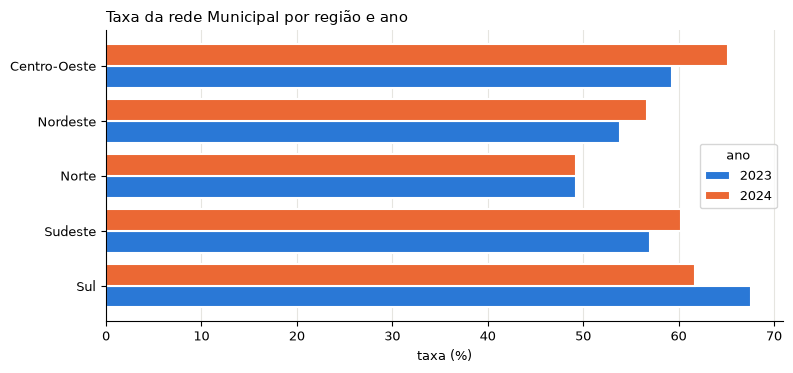

In [23]:
print("UFs sem microdados da rede Municipal:", {a: sorted(set(df_scr_municipio["sigla_uf"]) - set(df_mun_aluno.query("ano == @a and rede_id == @par_rede_municipal")["sigla_uf"])) for a in [2023, 2024]})
df_p5_regiao = taxa_ponderada(df_escola[df_escola["rede_id"] == par_rede_municipal], ["ano", "nome_regiao"], "peso_alfabetizados", "peso")
df_p5_regiao["ano"] = df_p5_regiao["ano"].astype(str)
plot_barras(df_p5_regiao, "nome_regiao", "taxa", hue="ano", titulo="Taxa da rede Municipal por região e ano", xlabel="taxa (%)")

**Conclusão:** É viável só como validação complementar, a diferença entre anos muda por região. A validação principal deve ser por grupos.

In [24]:
df_p6 = df_painel.dropna(subset=["variacao", "n_2023", "n_2024"]).query("n_2023 > 0 and n_2024 > 0").copy()
df_p6["var_esperada"] = (df_p6["taxa_2023"] * (100 - df_p6["taxa_2023"]) / df_p6["n_2023"]
                         + df_p6["taxa_2024"] * (100 - df_p6["taxa_2024"]) / df_p6["n_2024"])
df_p6_res = df_p6.groupby("porte", observed=True).agg(municipios=("variacao", "size"),
                                                       dp_observado=("variacao", "std"),
                                                       var_esperada=("var_esperada", "mean"))
df_p6_res["dp_ruido_amostral"] = np.sqrt(df_p6_res["var_esperada"])
df_p6_res["pct_variancia_ruido"] = 100 * df_p6_res["var_esperada"] / df_p6_res["dp_observado"] ** 2
df_p6_res.drop(columns="var_esperada")

,municipios,dp_observado,dp_ruido_amostral,pct_variancia_ruido
porte,,,,
<30,534,27.00,13.24,24.04
30-99,1826,18.40,8.35,20.59
100-299,1531,13.68,5.03,13.55
300-999,665,10.41,3.02,8.43
1000+,216,8.22,1.59,3.72


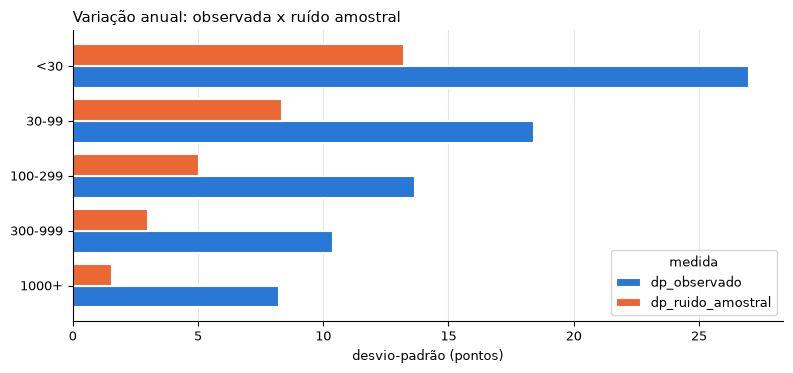

In [25]:
plot_barras(df_p6_res.reset_index()[["porte", "dp_observado", "dp_ruido_amostral"]]
            .melt("porte", var_name="medida", value_name="pontos"),
            "porte", "pontos", hue="medida", titulo="Variação anual: observada x ruído amostral", xlabel="desvio-padrão (pontos)")

**Resposta:** O ruído amostral não explica a variação: responde por 24% da variância nos menores municípios e 4% nos maiores. Mesmo acima de 1.000 alunos, o desvio é de 8,2 pontos. Os dados não permitem separar mudança real, efeito da aplicação e diferenças de comparabilidade entre os anos, e por isso a variação anual de um município não é tratada como evidência isolada.

### 6. Qualidade e integridade

#### Há duplicidades no grão de cada tabela?

In [26]:
par_graos = {"fato_aluno": ["ano", "id_aluno"],
             "fato_indicador_municipio": ["ano", "id_municipio", "rede_id", "serie"],
             "fato_indicador_uf": ["ano", "sigla_uf", "rede_id", "serie"],
             "fato_resultados": ["ano", "id_municipio", "rede_id"],
             "fato_meta": ["nivel_geografico", "local_id", "rede_id", "ano_referencia", "ano_meta"],
             "dim_municipio": ["id_municipio"], "dim_uf": ["sigla_uf"], "dim_rede": ["rede_id"], "dim_tempo": ["ano"]}
par_tabelas_gold = {"fato_aluno": df_scr_aluno, "fato_indicador_municipio": df_scr_indicador_municipio, "fato_indicador_uf": df_scr_indicador_uf,
                    "fato_resultados": df_scr_resultados, "fato_meta": df_scr_meta, "dim_municipio": df_scr_municipio,
                    "dim_uf": df_scr_uf, "dim_rede": df_scr_rede}
df_q1 = pd.DataFrame([{"tabela": t, "linhas": len(d), "duplicadas": d.duplicated(subset=g).sum()}
                      for t, g in par_graos.items()
                      for d in [par_tabelas_gold[t] if t in par_tabelas_gold else ler_tabela(f"{par_gold}.{t}")]])
df_q1

,tabela,linhas,duplicadas
0,fato_aluno,3867999,0
1,fato_indicador_municipio,23995,0
2,fato_indicador_uf,145,0
3,fato_resultados,23995,0
4,fato_meta,75254,0
5,dim_municipio,5551,0
6,dim_uf,25,0
7,dim_rede,5,0
8,dim_tempo,8,0


**Resposta:** Não há duplicidades nos grãos testados.

#### Todas as chaves têm correspondência nas dimensões?

In [27]:
def chaves_orfas(relacao, chaves, referencia):
    chaves = pd.Series(chaves).dropna().drop_duplicates()
    return {"relacao": relacao, "chaves": len(chaves), "orfas": (~chaves.isin(referencia)).sum()}


meta_mun = df_scr_meta.loc[df_scr_meta["nivel_geografico"] == "municipio", "local_id"]
meta_uf = df_scr_meta.loc[df_scr_meta["nivel_geografico"] == "uf", "local_id"]
pd.DataFrame([chaves_orfas("aluno x municipio", df_scr_aluno["id_municipio"], df_scr_municipio["id_municipio"]),
              chaves_orfas("indicador x municipio", df_scr_indicador_municipio["id_municipio"], df_scr_municipio["id_municipio"]),
              chaves_orfas("meta municipal x municipio", meta_mun, df_scr_municipio["id_municipio"]),
              chaves_orfas("meta UF x UF", meta_uf, df_scr_uf["sigla_uf"]),
              chaves_orfas("dim_municipio x dim_uf", df_scr_municipio["sigla_uf"], df_scr_uf["sigla_uf"])])

,relacao,chaves,orfas
0,aluno x municipio,5548,0
1,indicador x municipio,5550,0
2,meta municipal x municipio,5352,0
3,meta UF x UF,27,2
4,dim_municipio x dim_uf,26,1


**Resposta:** Só faltam DF e RR em `dim_uf`: as metas dessas UFs e o DF de `dim_municipio` ficam órfãos. A lacuna é da camada Gold e está registrada nas limitações e nas evoluções futuras do projeto.

#### Por que há municípios com indicador, mas sem alunos em 2023?

In [28]:
df_q4 = df_painel[df_painel["taxa_2023"].notna()].assign(sem_alunos=lambda d: d["n_2023"].isna())
df_q4.groupby("sem_alunos").agg(municipios=("id_municipio", "size"), taxa_2023=("taxa_2023", "mean"), taxa_2024=("taxa_2024", "mean"), n_2024=("n_2024", "median"))

,municipios,taxa_2023,taxa_2024,n_2024
sem_alunos,,,,
False,4821,60.18,62.72,101.00
True,627,61.04,64.05,122.00


In [29]:
pd.crosstab(df_q4["sigla_uf"], df_q4["sem_alunos"]).query("`True` > 0")

sem_alunos,False,True
sigla_uf,,
SP,0,627


**Resposta:** Os 627 municípios são todos de SP: não há microdados de 2023 para SP nem para AC, em nenhuma rede. A Gold não registra o motivo, e a lacuna é tratada como limitação de cobertura.

#### Os pesos de 2023 e 2024 são comparáveis?

In [30]:
df_scr_aluno.groupby("ano")["peso_aluno"].agg(
    p01=lambda s: s.quantile(.01), p50=lambda s: s.quantile(.5), p99=lambda s: s.quantile(.99), maximo="max",
    soma_pesos="sum", avaliados="count", alunos="size", pct_peso_maior_5=lambda s: 100 * (s > 5).sum() / s.count()).reset_index()

,ano,p01,p50,p99,maximo,soma_pesos,avaliados,alunos,pct_peso_maior_5
0,2023,0.72,1.09,2.16,142.55,"1,743,618.14",1502809,1747439,0.08
1,2024,1.00,1.09,1.79,29.83,"2,109,174.87",1851852,2120560,0.01


**Resposta:** Não totalmente: a mediana é igual (1,09), mas 2023 tem pesos abaixo de 1 e máximo de 142,55. O peso não entra como variável: é usado como `sample_weight`, limitado a 5, no modelo de aluno.

#### As proporções por nível existem em 2023?

In [31]:
par_niveis = [f"proporcao_aluno_nivel_{i}" for i in range(9)]
df_scr_indicador_municipio.groupby("ano")[par_niveis].apply(lambda d: d.notna().mean() * 100).T

ano,2023,2024
proporcao_aluno_nivel_0,0.00,100.00
proporcao_aluno_nivel_1,0.00,100.00
proporcao_aluno_nivel_2,0.00,100.00
proporcao_aluno_nivel_3,0.00,100.00
proporcao_aluno_nivel_4,0.00,100.00
proporcao_aluno_nivel_5,0.00,100.00
proporcao_aluno_nivel_6,0.00,100.00
proporcao_aluno_nivel_7,0.00,100.00
proporcao_aluno_nivel_8,0.00,100.00


In [32]:
(ler_tabela(f"{par_source_project}.silver.municipio", ["ano", "proporcao_aluno_nivel_0"])
 .groupby("ano").agg(linhas=("ano", "size"), com_nivel=("proporcao_aluno_nivel_0", "count")).reset_index())

,ano,linhas,com_nivel
0,2023,11547,0
1,2024,12448,12448


**Resposta:** Não: as proporções faltam em 2023 já na Silver. Só servem para análises de 2024.

### 7. Alvo e população

#### Qual é o balanceamento do alvo?

In [33]:
df_a1 = df_escola.groupby(["ano", "rede_id"], as_index=False)[["n_avaliados", "n_alfabetizados", "peso", "peso_alfabetizados"]].sum()
df_a1["pct_positivo"] = 100 * df_a1["n_alfabetizados"] / df_a1["n_avaliados"]
df_a1["pct_positivo_ponderado"] = 100 * df_a1["peso_alfabetizados"] / df_a1["peso"]
df_a1.merge(df_scr_rede, on="rede_id")[["ano", "rede", "n_avaliados", "pct_positivo", "pct_positivo_ponderado"]]

,ano,rede,n_avaliados,pct_positivo,pct_positivo_ponderado
0,2023,Estadual,131522,61.33,60.09
1,2023,Municipal,1371287,58.10,57.21
2,2024,Estadual,241074,62.54,61.65
3,2024,Municipal,1610754,59.37,58.82
4,2024,Privada,24,66.67,66.67


**Conclusão:** O alvo é levemente desbalanceado (58% a 63% de positivos). A rede Privada (24 alunos) deve sair.

#### Distribuição da proficiência

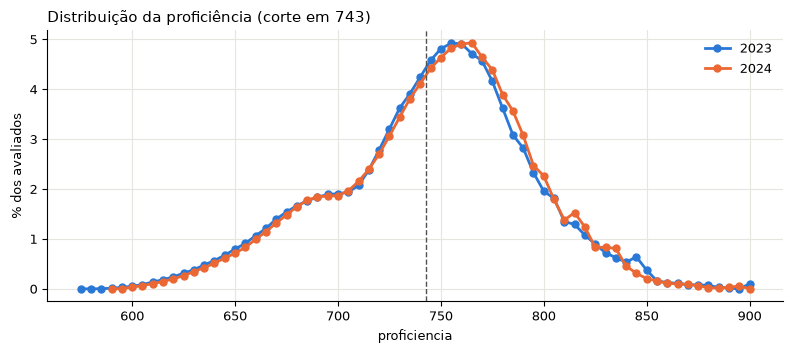

In [34]:
df_avaliados = df_scr_aluno.dropna(subset=["proficiencia"])
df_a2 = (df_avaliados.assign(proficiencia=(np.floor(df_avaliados["proficiencia"] / 5) * 5).astype(int))
         .groupby(["ano", "proficiencia"], as_index=False).size().rename(columns={"size": "alunos"}))
df_a2["pct_alunos"] = 100 * df_a2["alunos"] / df_a2.groupby("ano")["alunos"].transform("sum")
plot_linhas(df_a2, "proficiencia", "pct_alunos", hue="ano", referencia=par_corte, titulo="Distribuição da proficiência (corte em 743)", ylabel="% dos avaliados")

**Conclusão:** As distribuições de 2023 e 2024 são muito parecidas, com pico logo acima do corte e cauda à esquerda. Portanto, a variação de taxa não vem de mudança na forma geral da distribuição nacional.

#### Quantos alunos estão perto do corte?

In [35]:
distancia_corte = (df_avaliados["proficiencia"] - par_corte).abs()
pd.DataFrame({f"pct_{p}_pontos": 100 * (distancia_corte <= p).groupby(df_avaliados["ano"]).mean() for p in [5, 10, 25]}).assign(
    dp_proficiencia=df_avaliados.groupby("ano")["proficiencia"].std()).reset_index()

,ano,pct_5_pontos,pct_10_pontos,pct_25_pontos,dp_proficiencia
0,2023,8.56,17.10,40.89,48.23
1,2024,8.31,16.57,39.92,47.04


**Conclusão:** Cerca de 17% dos alunos estão a até 10 pontos do corte e 40% a até 25 pontos.

#### A presença varia por região, rede, porte e escola?

In [36]:
df_a4 = df_mun_aluno[df_mun_aluno["ano"] == 2024]
pd.concat([df_a4.assign(eixo=eixo, grupo=df_a4[col].astype(str)).groupby(["eixo", "grupo"])[["n_presentes", "n_total"]].sum()
           for eixo, col in [("região", "nome_regiao"), ("rede", "rede_id"), ("porte", "porte")]]).assign(
    taxa_presenca=lambda d: 100 * d["n_presentes"] / d["n_total"])

n_presentes  n_total  taxa_presenca
eixo   grupo                                            
região Centro-Oeste       175459   197156          89.00
       Nordeste           465987   505461          92.19
       Norte              188119   226251          83.15
       Sudeste            744675   845966          88.03
       Sul                278548   345726          80.57
rede   2                  241173   280258          86.05
       3                 1611591  1840277          87.57
       4                      24       25          96.00
porte  100-299            330940   368379          89.84
       1000+              920606  1071584          85.91
       30-99              144264   160827          89.70
       300-999            437007   494160          88.43
       <30                 19971    25610          77.98

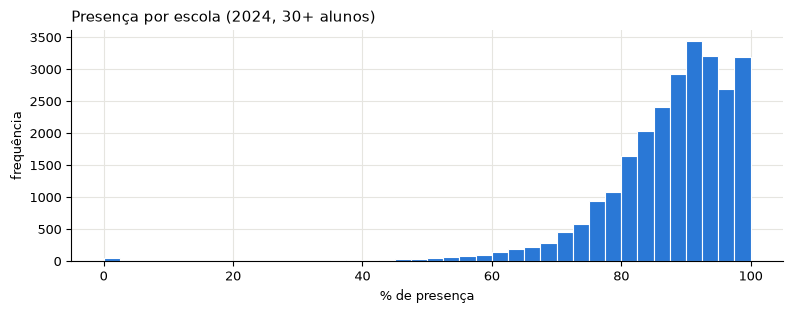

In [37]:
df_a4_escola = df_escola[(df_escola["ano"] == 2024) & (df_escola["n_total"] >= par_min_alunos)]
plot_hist(100 * df_a4_escola["n_presentes"] / df_a4_escola["n_total"], titulo="Presença por escola (2024, 30+ alunos)", xlabel="% de presença")

**Conclusão:** Sim: Sul (80,6%) e Norte (83,2%) têm menos presença que Nordeste (92,2%), e municípios com menos de 30 avaliados têm 78,0%.

#### Municípios com menor presença têm taxas diferentes?

In [38]:
df_a5 = df_mun_aluno[df_mun_aluno["rede_id"] == par_rede_municipal]
df_a5.groupby("ano")[["taxa_presenca", "taxa_ponderada"]].corr(method="spearman").xs("taxa_presenca", level=1)[["taxa_ponderada"]]

,taxa_ponderada
ano,
2023,0.25
2024,0.29


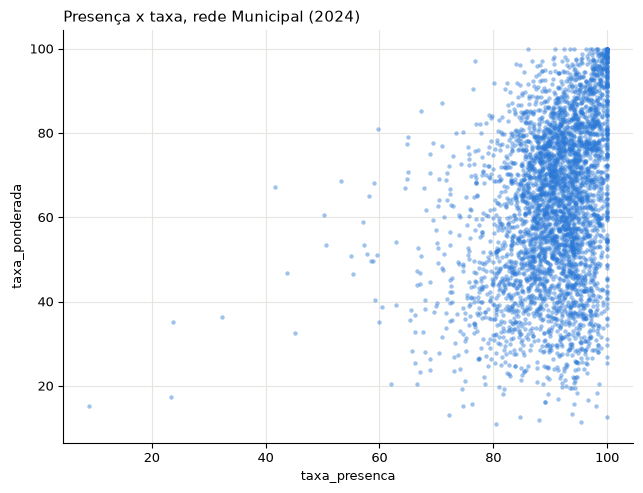

In [39]:
plot_dispersao(df_a5[(df_a5["ano"] == 2024) & (df_a5["n_avaliados"] >= par_min_alunos)], "taxa_presenca", "taxa_ponderada",
               titulo="Presença x taxa, rede Municipal (2024)")

**Conclusão:** Sim, com associação moderada (Spearman de 0,25 a 0,29). A presença municipal só pode entrar defasada.

In [40]:
df_a6 = df_escola.groupby("ano")[["n_total", "n_avaliados", "n_alfabetizados", "peso", "peso_alfabetizados"]].sum()
pd.DataFrame({"todos_sem_peso": 100 * df_a6["n_alfabetizados"] / df_a6["n_total"],
              "avaliados_sem_peso": 100 * df_a6["n_alfabetizados"] / df_a6["n_avaliados"],
              "avaliados_com_peso": 100 * df_a6["peso_alfabetizados"] / df_a6["peso"]})

,todos_sem_peso,avaliados_sem_peso,avaliados_com_peso
ano,,,
2023,50.21,58.39,57.46
2024,52.21,59.78,59.20


In [41]:
df_a6_erro = df_mun_aluno.merge(df_scr_indicador_municipio[["ano", "id_municipio", "rede_id", "taxa_alfabetizacao"]], on=["ano", "id_municipio", "rede_id"])
pd.Series({"todos_sem_peso": (100 * df_a6_erro["n_alfabetizados"] / df_a6_erro["n_total"] - df_a6_erro["taxa_alfabetizacao"]).abs().mean(),
           "avaliados_sem_peso": (100 * df_a6_erro["n_alfabetizados"] / df_a6_erro["n_avaliados"] - df_a6_erro["taxa_alfabetizacao"]).abs().mean(),
           "avaliados_com_peso": (df_a6_erro["taxa_ponderada"] - df_a6_erro["taxa_alfabetizacao"]).abs().mean()}, name="erro_abs_medio_vs_oficial").to_frame()

,erro_abs_medio_vs_oficial
todos_sem_peso,5.93
avaliados_sem_peso,0.68
avaliados_com_peso,0.04


**Resposta:** A definição correta é avaliados com peso (erro de 0,04 ponto frente à taxa oficial), contra 0,68 sem peso e 5,93 incluindo não avaliados.

### 8. Território e rede

#### Como a taxa varia por região, UF e rede?

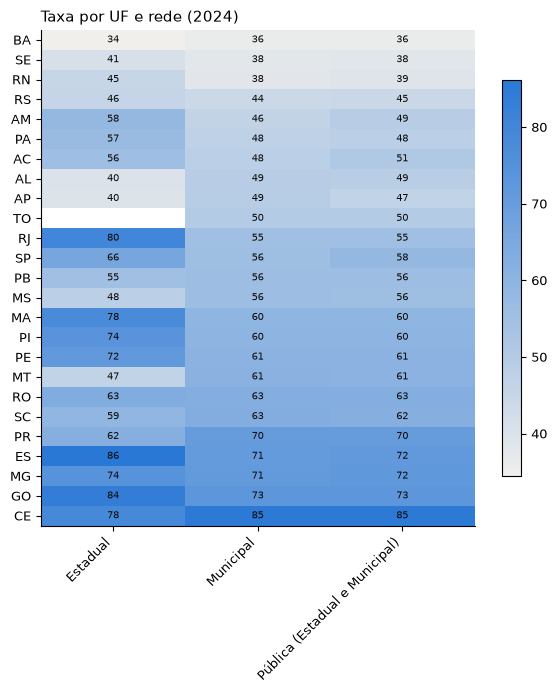

In [42]:
df_t1 = df_scr_indicador_uf.merge(df_scr_rede, on="rede_id").query("ano == 2024 and rede_id in ['2', '3', '5']")
plot_heatmap(df_t1.pivot(index="sigla_uf", columns="rede", values="taxa_alfabetizacao").sort_values("Municipal"),
             titulo="Taxa por UF e rede (2024)", fmt=".0f", figsize=(6, 7))

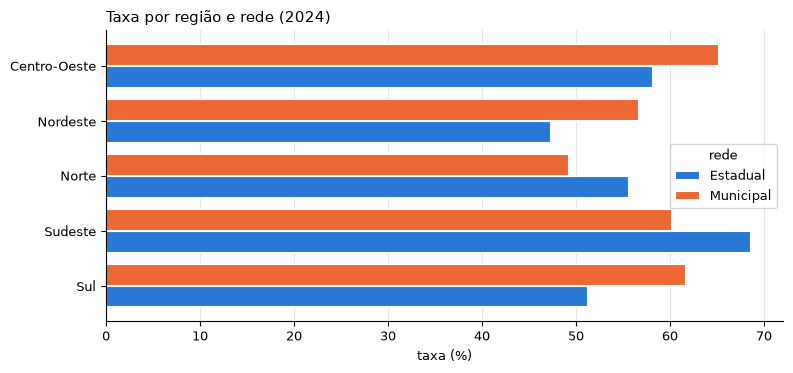

In [43]:
df_t1_regiao = taxa_ponderada(df_escola[(df_escola["ano"] == 2024) & df_escola["rede_id"].isin(["2", "3"])],
                              ["nome_regiao", "rede_id"], "peso_alfabetizados", "peso").merge(df_scr_rede, on="rede_id")
plot_barras(df_t1_regiao, "nome_regiao", "taxa", hue="rede", titulo="Taxa por região e rede (2024)", xlabel="taxa (%)")

**Resposta:** A rede Municipal vai de 36% (BA) a 85% (CE) em 2024. A diferença entre UFs é bem maior que entre regiões, por isso UF deve ser preferida a região.

#### A diferença entre as redes persiste dentro do mesmo município?

In [44]:
df_t2 = (df_mun_aluno[(df_mun_aluno["ano"] == 2024) & (df_mun_aluno["n_avaliados"] >= par_min_alunos) & df_mun_aluno["rede_id"].isin(["2", "3"])]
         .pivot(index=["id_municipio", "sigla_uf", "nome_regiao"], columns="rede_id", values="taxa_ponderada")
         .dropna().reset_index().rename(columns={"2": "estadual", "3": "municipal"}))
df_t2["dif_estadual_municipal"] = df_t2["estadual"] - df_t2["municipal"]
print("Municípios com as duas redes:", len(df_t2))
print("Diferença média pareada:", round(df_t2["dif_estadual_municipal"].mean(), 2), "| % com estadual maior:", round(100 * (df_t2["dif_estadual_municipal"] > 0).mean(), 1))

Municípios com as duas redes: 589
Diferença média pareada: 5.62 | % com estadual maior: 66.4


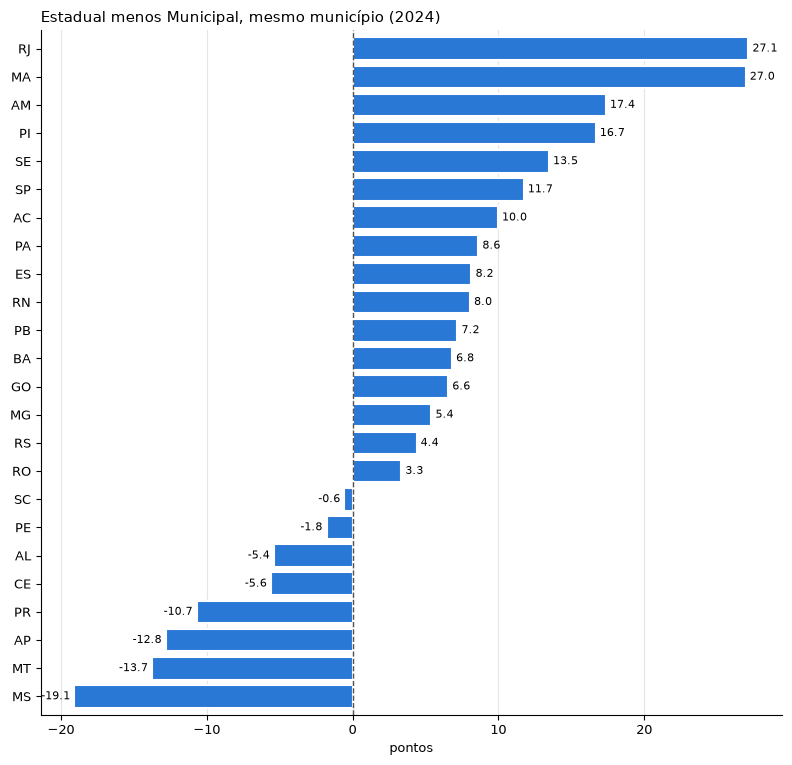

In [45]:
plot_barras(df_t2.groupby("sigla_uf", as_index=False)["dif_estadual_municipal"].mean().sort_values("dif_estadual_municipal", ascending=False),
            "sigla_uf", "dif_estadual_municipal", titulo="Estadual menos Municipal, mesmo município (2024)", xlabel="pontos", referencia=0)

**Resposta:** Em média, sim: nos 589 municípios com as duas redes, a Estadual fica 5,6 pontos acima. Mas o sinal muda por UF (de +27,1 no RJ a -19,1 no MS), portanto o efeito depende da UF.

#### Em quais UFs a desigualdade interna é maior?

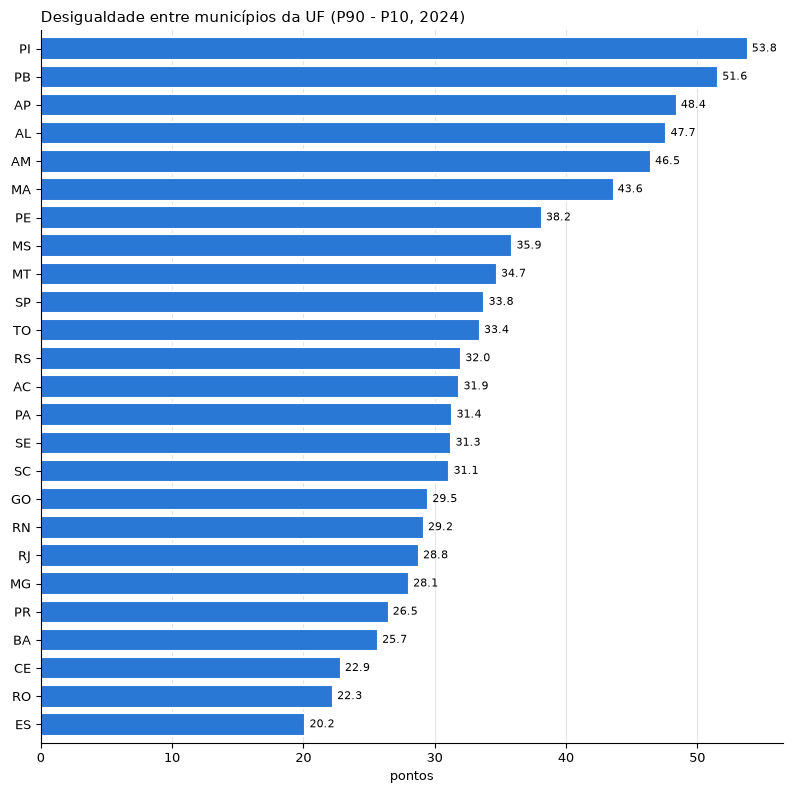

In [46]:
df_t3 = df_painel[df_painel["n_2024"] >= par_min_alunos].groupby("sigla_uf")["taxa_2024"].agg(
    municipios="size", media="mean", dp="std", p10=lambda s: s.quantile(.1), p90=lambda s: s.quantile(.9))
df_t3["amplitude_p90_p10"] = df_t3["p90"] - df_t3["p10"]
df_t3 = df_t3.sort_values("amplitude_p90_p10", ascending=False)
plot_barras(df_t3.reset_index(), "sigla_uf", "amplitude_p90_p10", titulo="Desigualdade entre municípios da UF (P90 - P10, 2024)", xlabel="pontos")

**Resposta:** PI (53,8), PB (51,6) e AP (48,4) têm a maior amplitude; ES (20,2) e RO (22,3), a menor.

#### Quanto da variância fica entre escolas, em comparação com municípios?

In [47]:
df_t4 = df_escola[df_escola["ano"] == 2024]
icc_municipio = icc_binario(df_t4, "id_municipio", "n_avaliados", "n_alfabetizados")
icc_escola = icc_binario(df_t4, "id_escola", "n_avaliados", "n_alfabetizados")
print(f"Entre municípios: {icc_municipio:.1%} | Entre escolas: {icc_escola:.1%} | Adicional da escola: {icc_escola - icc_municipio:.1%} | Dentro da escola: {1 - icc_escola:.1%}")

Entre municípios: 9.4% | Entre escolas: 14.8% | Adicional da escola: 5.5% | Dentro da escola: 85.2%


**Resposta:** As escolas acrescentam 5,5 pontos ao ICC dos municípios (9,4%). Elas importam, mas sem ID estável entre anos só servem para separar grupos.

#### Existem escolas muito acima ou abaixo do próprio município?

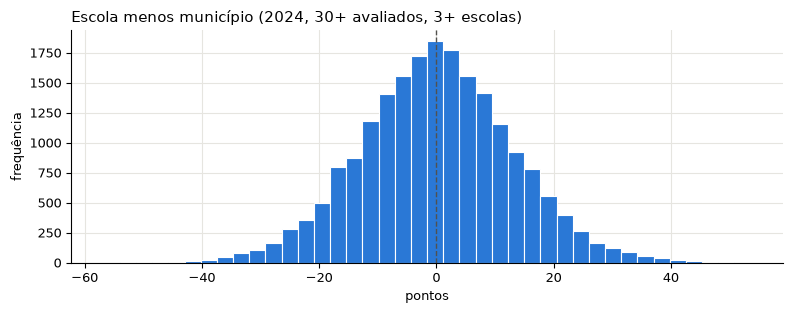

% escolas a 20+ pontos da média municipal: 12.2


In [48]:
df_t5 = df_escola[(df_escola["ano"] == 2024) & (df_escola["n_avaliados"] >= par_min_alunos)].copy()
df_t5["taxa_escola"] = 100 * df_t5["n_alfabetizados"] / df_t5["n_avaliados"]
g = df_t5.groupby("id_municipio")
df_t5["taxa_mun"] = 100 * g["n_alfabetizados"].transform("sum") / g["n_avaliados"].transform("sum")
df_t5["desvio"] = df_t5["taxa_escola"] - df_t5["taxa_mun"]
plot_hist(df_t5.loc[g["id_escola"].transform("size") >= 3, "desvio"], titulo="Escola menos município (2024, 30+ avaliados, 3+ escolas)", xlabel="pontos", referencia=0)
print("% escolas a 20+ pontos da média municipal:", round(100 * (df_t5.loc[g["id_escola"].transform("size") >= 3, "desvio"].abs() >= 20).mean(), 1))

**Resposta:** Sim: 12,2% das escolas ficam a 20 pontos ou mais da média municipal, o que aponta casos para aprofundar localmente.

#### Há autocorrelação espacial entre municípios vizinhos?

In [49]:
df_t6 = df_base.dropna(subset=["taxa_2024", "lon", "lat"])
df_t6 = df_t6[df_t6["n_2024"] >= par_min_alunos].copy()
df_t6["taxa_sem_uf"] = df_t6["taxa_2024"] - df_t6.groupby("sigla_uf")["taxa_2024"].transform("mean")
print("I de Moran (8 vizinhos):", round(moran_i(df_t6["taxa_2024"], df_t6[["lon", "lat"]].values), 3))
print("I de Moran sem a média da UF:", round(moran_i(df_t6["taxa_sem_uf"], df_t6[["lon", "lat"]].values), 3))

I de Moran (8 vizinhos): 0.578
I de Moran sem a média da UF: 0.157


**Resposta:** Sim, forte (I de Moran 0,58), caindo para 0,16 sem a média da UF. A validação deve evitar vizinhos em treino e teste, por exemplo agrupando por UF ou mesorregião.

### 9. Evolução temporal

#### Quais municípios e UFs mais avançaram ou recuaram?

UFs sem microdados nos dois anos: ['AC', 'SP']


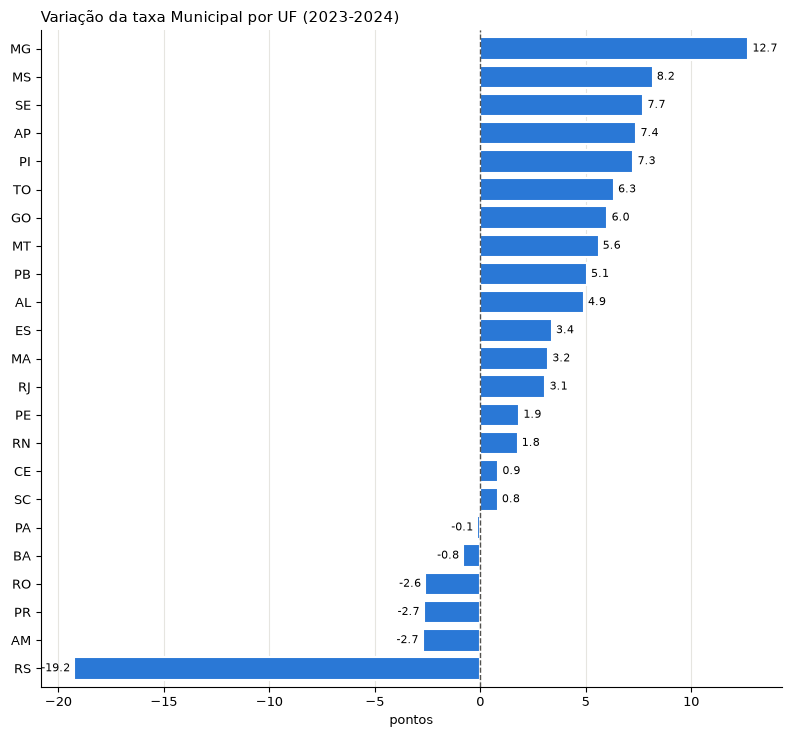

In [50]:
df_e1_uf = taxa_ponderada(df_escola[df_escola["rede_id"] == par_rede_municipal], ["ano", "sigla_uf"], "peso_alfabetizados", "peso").pivot(index="sigla_uf", columns="ano", values="taxa")
df_e1_uf["variacao"] = df_e1_uf[2024] - df_e1_uf[2023]
print("UFs sem microdados nos dois anos:", df_e1_uf.index[df_e1_uf["variacao"].isna()].tolist())
plot_barras(df_e1_uf.dropna(subset=["variacao"]).reset_index().sort_values("variacao", ascending=False), "sigla_uf", "variacao",
            titulo="Variação da taxa Municipal por UF (2023-2024)", xlabel="pontos", referencia=0)

In [51]:
df_e1 = df_painel[(df_painel["n_2023"] >= 100) & (df_painel["n_2024"] >= 100)].sort_values("variacao")
pd.concat([df_e1.head(10), df_e1.tail(10)])[["nome_municipio", "sigla_uf", "n_2024", "taxa_2023", "taxa_2024", "variacao"]]

,nome_municipio,sigla_uf,n_2024,taxa_2023,taxa_2024,variacao
447,Anapurus,MA,109,91.05,34.63,-56.42
1445,Uiraúna,PB,110,98.05,44.45,-53.60
580,Pirapemas,MA,103,83.02,42.38,-40.64
4825,Nova Petrópolis,RS,132,91.67,52.30,-39.37
645,Urbano Santos,MA,277,76.76,38.63,-38.13
4940,São Luiz Gonzaga,RS,169,80.28,42.30,-37.98
549,Matões,MA,269,72.34,34.52,-37.82
5086,Mundo Novo,MS,213,83.81,46.46,-37.35
96,Envira,AM,138,56.52,19.30,-37.22
4628,Canela,RS,288,78.68,42.20,-36.48


**Resposta:** MG (+12,7) lidera, e RS (-19,2) é o recuo mais forte. Há oscilações municipais de até 62 pontos, mesmo com 100+ alunos, por isso variações de municípios isolados não são usadas como insight.

#### Quem parte de taxas baixas sobe mais?

In [52]:
df_e2 = df_painel.dropna(subset=["variacao"]).copy()
df_e2["quartil_2023"] = pd.qcut(df_e2["taxa_2023"], 4, labels=["Q1 (menor)", "Q2", "Q3", "Q4 (maior)"])
print("Correlação 2023 x 2024:", round(df_e2["taxa_2023"].corr(df_e2["taxa_2024"]), 3), "| 2023 x variação:", round(df_e2["taxa_2023"].corr(df_e2["variacao"]), 3))
df_e2.groupby("quartil_2023", observed=True)[["taxa_2023", "taxa_2024", "variacao"]].mean()

Correlação 2023 x 2024: 0.636 | 2023 x variação: -0.449


,taxa_2023,taxa_2024,variacao
quartil_2023,,,
Q1 (menor),34.30,45.68,11.38
Q2,53.66,60.03,6.37
Q3,67.57,68.46,0.90
Q4 (maior),85.30,77.33,-7.98


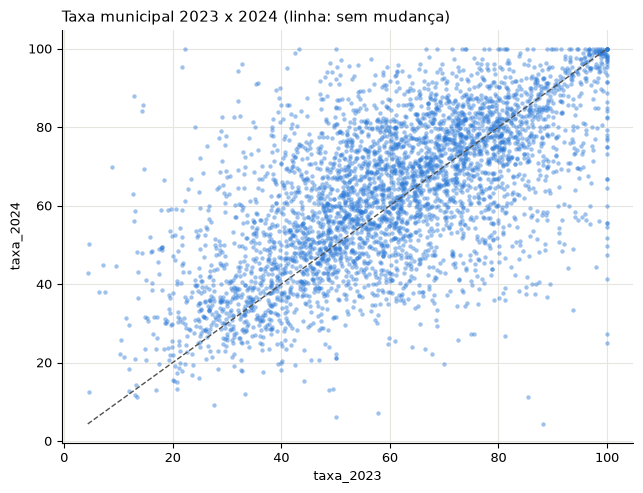

In [53]:
plot_dispersao(df_e2, "taxa_2023", "taxa_2024", diagonal=True, titulo="Taxa municipal 2023 x 2024 (linha: sem mudança)")

**Resposta:** Sim: o quartil inferior sobe 11,4 pontos e o superior cai 8,0 (r = -0,45). Há forte regressão à média, então a taxa defasada é útil, mas não basta.

#### A variação anual é maior em municípios pequenos?

In [54]:
df_e3 = df_painel.dropna(subset=["variacao", "porte"]).assign(variacao_abs=lambda d: d["variacao"].abs())
df_e3.groupby("porte", observed=True).agg(municipios=("variacao", "size"), variacao_media=("variacao", "mean"),
                                           mediana_abs=("variacao_abs", "median"),
                                           pct_acima_20=("variacao_abs", lambda s: 100 * (s >= 20).mean()))

,municipios,variacao_media,mediana_abs,pct_acima_20
porte,,,,
<30,593,-0.77,18.97,47.39
30-99,2044,3.32,11.42,26.22
100-299,1703,3.20,8.45,14.27
300-999,777,2.74,5.89,7.08
1000+,279,1.82,4.36,2.87


**Resposta:** Sim: a variação mediana absoluta cai de 19,0 pontos (<30 avaliados) para 4,4 (1000+).

#### As relações entre variáveis são estáveis entre 2023 e 2024?

In [55]:
par_estaveis = ["idhm", "renda_pc", "prop_pobreza_criancas", "indice_gini", "populacao", "pib_per_capita",
                "distorcao_idade_serie", "taxa_aprovacao", "pct_docente_superior", "pct_docente_adequado", "alunos_turma_2ano"]
df_e5 = pd.DataFrame({ano: [df_base[v].corr(df_base[f"taxa_{ano}"], method="spearman") for v in par_estaveis] for ano in [2023, 2024]}, index=par_estaveis)
df_e5["diferenca"] = df_e5[2024] - df_e5[2023]
df_e5

,2023,2024,diferenca
idhm,0.29,0.21,-0.08
renda_pc,0.28,0.16,-0.11
prop_pobreza_criancas,-0.29,-0.21,0.08
indice_gini,-0.25,-0.22,0.03
populacao,-0.19,-0.19,0.00
pib_per_capita,0.21,0.12,-0.09
distorcao_idade_serie,-0.36,-0.39,-0.04
taxa_aprovacao,0.33,0.42,0.09
pct_docente_superior,0.21,0.25,0.03
pct_docente_adequado,0.11,0.13,0.02


**Resposta:** Em grande parte, sim: nenhuma correlação muda mais que 0,11. As socioeconômicas enfraquecem um pouco em 2024, e as de fluxo escolar seguem como as mais fortes.

### 10. Metas

#### Qual é a proporção de municípios que atingiram a meta de 2024?

Brasil: 2788 de 5232 (53.3%)


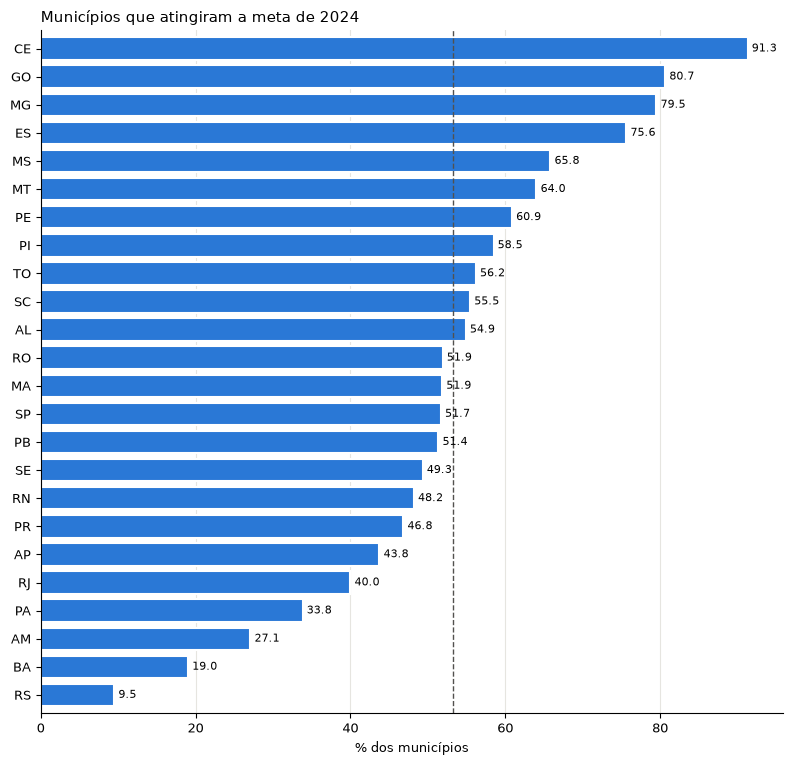

In [56]:
df_m1 = df_painel.dropna(subset=["atingiu_meta_ano"]).copy()
df_m1["atingiu"] = df_m1["atingiu_meta_ano"].astype(float) * 100
print("Brasil:", int(df_m1["atingiu_meta_ano"].sum()), "de", len(df_m1), f"({df_m1['atingiu'].mean():.1f}%)")
plot_barras(df_m1.groupby("sigla_uf", as_index=False)["atingiu"].mean().sort_values("atingiu", ascending=False), "sigla_uf", "atingiu",
            titulo="Municípios que atingiram a meta de 2024", xlabel="% dos municípios", referencia=df_m1["atingiu"].mean())

In [57]:
df_m1.groupby("nome_regiao").agg(municipios=("atingiu", "size"), atingiu=("atingiu", "mean"), taxa=("taxa_2024", "mean"), meta=("meta_ano", "mean")).sort_values("atingiu")

,municipios,atingiu,taxa,meta
nome_regiao,,,,
Sul,1054,33.87,64.68,72.31
Norte,389,43.70,50.24,50.95
Nordeste,1738,50.12,56.78,55.67
Sudeste,1590,66.23,69.98,64.23
Centro-Oeste,461,73.10,72.32,65.63


**Resposta:** 53,3% (2.788 de 5.232), de 91,3% no CE a 9,5% no RS.

#### Quão desafiadora é cada meta em relação à taxa de 2023?

count   5,232.00
mean        1.67
std         5.85
min       -32.01
25%         0.73
50%         3.15
75%         5.39
max         7.22
Correlação meta x taxa 2023: 0.979


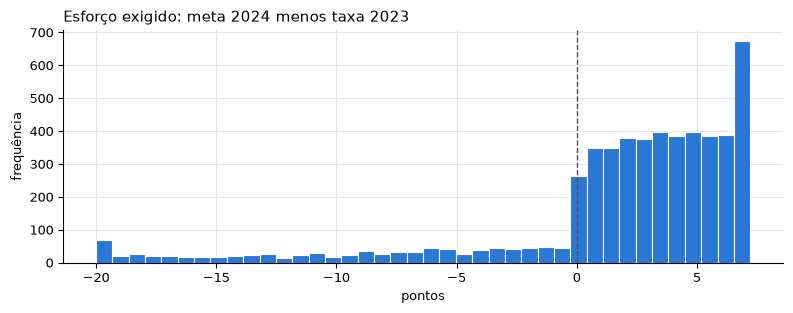

In [58]:
df_m2 = df_painel.dropna(subset=["meta_ano", "taxa_2023"]).copy()
df_m2["esforco"] = df_m2["meta_ano"] - df_m2["taxa_2023"]
print(df_m2["esforco"].describe().round(2).to_string())
print("Correlação meta x taxa 2023:", round(df_m2["meta_ano"].corr(df_m2["taxa_2023"]), 3))
plot_hist(df_m2["esforco"].clip(-20, 30), titulo="Esforço exigido: meta 2024 menos taxa 2023", xlabel="pontos", referencia=0)

**Resposta:** Para a maioria, pouco acima da taxa de 2023 (mediana de 3,2 pontos, máximo de 7,2). A meta acompanha a taxa de 2023 (r = 0,979), e parte dos municípios já estava acima dela.

#### Atingir a meta é mais fácil para quem partiu de taxa baixa?

In [59]:
df_m3 = df_m2.dropna(subset=["atingiu_meta_ano"]).copy()
df_m3["atingiu"] = df_m3["atingiu_meta_ano"].astype(float) * 100
df_m3["quartil_2023"] = pd.qcut(df_m3["taxa_2023"], 4, labels=["Q1 (menor)", "Q2", "Q3", "Q4 (maior)"])
df_m3.groupby("quartil_2023", observed=True).agg(municipios=("atingiu", "size"), taxa_2023=("taxa_2023", "mean"), meta=("meta_ano", "mean"), esforco=("esforco", "mean"), atingiu=("atingiu", "mean"))

,municipios,taxa_2023,meta,esforco,atingiu
quartil_2023,,,,,
Q1 (menor),1309,34.61,41.11,6.50,55.46
Q2,1307,53.98,58.27,4.29,55.24
Q3,1308,67.88,69.84,1.96,50.99
Q4 (maior),1308,85.48,79.40,-6.08,51.45


**Resposta:** Pouco: atingem a meta 55,5% do quartil inferior e 51,5% do superior. O desenho das metas nivela os grupos, então "não atingir" não equivale a taxa baixa.

#### Qual é o ritmo exigido até 80% em 2030?

Variação mediana observada 2023-2024: 2.49
% já acima de 80%: 21.3
% com ritmo exigido acima do mediano: 51.7
% com ritmo exigido de 5+ pontos ao ano: 27.0


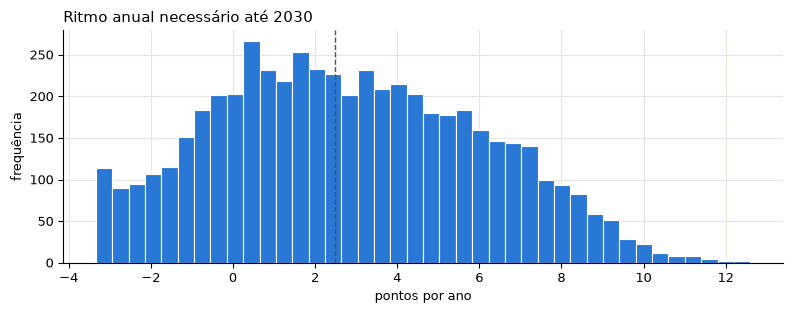

In [60]:
df_m4 = df_painel.dropna(subset=["gap_ate_2030"]).copy()
df_m4["ritmo_anual"] = df_m4["gap_ate_2030"] / 6
ritmo_mediano = df_painel["variacao"].median()
print("Variação mediana observada 2023-2024:", round(ritmo_mediano, 2))
print("% já acima de 80%:", round(100 * (df_m4["gap_ate_2030"] <= 0).mean(), 1))
print("% com ritmo exigido acima do mediano:", round(100 * (df_m4["ritmo_anual"] > ritmo_mediano).mean(), 1))
print("% com ritmo exigido de 5+ pontos ao ano:", round(100 * (df_m4["ritmo_anual"] >= 5).mean(), 1))
plot_hist(df_m4["ritmo_anual"], titulo="Ritmo anual necessário até 2030", xlabel="pontos por ano", referencia=ritmo_mediano)

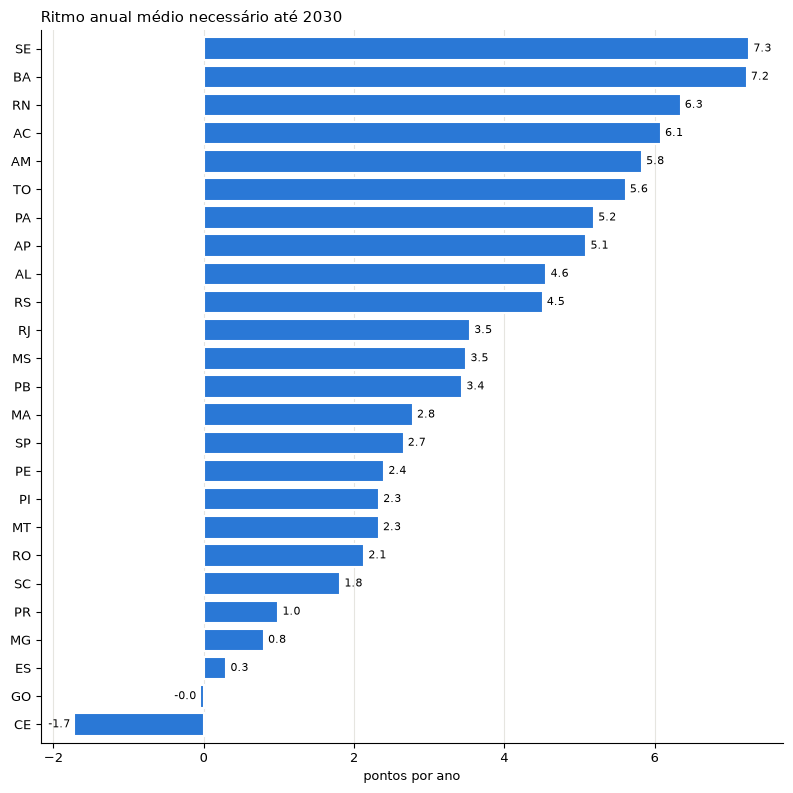

In [61]:
df_m4_uf = df_m4.groupby("sigla_uf", as_index=False)["ritmo_anual"].mean()
plot_barras(df_m4_uf.sort_values("ritmo_anual", ascending=False), "sigla_uf", "ritmo_anual", titulo="Ritmo anual médio necessário até 2030", xlabel="pontos por ano")

**Resposta:** 51,7% precisam de ritmo acima da variação mediana (2,5 pontos ao ano), 27,0% precisam de 5+ pontos ao ano, e 21,3% já estão em 80%+. SE (7,3) e BA (7,2) têm o maior ritmo médio.

#### As metas municipais são coerentes com as estaduais e nacional?

In [62]:
df_m5 = df_scr_meta[(df_scr_meta["ano_referencia"] == 2024)]
df_m5_mun = df_m5[df_m5["nivel_geografico"] == "municipio"].merge(df_scr_municipio, left_on="local_id", right_on="id_municipio")
df_m5_mun = df_m5_mun.groupby(["sigla_uf", "ano_meta"], as_index=False)["valor_meta"].mean()
df_m5_uf = df_m5[df_m5["nivel_geografico"] == "uf"].rename(columns={"local_id": "sigla_uf"})
df_m5_c = df_m5_mun.merge(df_m5_uf, on=["sigla_uf", "ano_meta"], suffixes=("_mun", "_uf"))
df_m5_c["dif"] = df_m5_c["valor_meta_mun"] - df_m5_c["valor_meta_uf"]
df_m5_c[df_m5_c["ano_meta"] < 2030].groupby("ano_meta").agg(ufs=("dif", "size"), corr=("valor_meta_mun", lambda s: s.corr(df_m5_c.loc[s.index, "valor_meta_uf"])), dif_media=("dif", "mean"), dif_abs=("dif", lambda s: s.abs().mean()))

,ufs,corr,dif_media,dif_abs
ano_meta,,,,
2024,24,0.97,1.03,2.33
2025,25,0.96,0.22,2.20
2026,25,0.96,0.10,1.75
2027,25,0.96,0.07,1.27
2028,25,0.95,0.08,0.83
2029,25,0.95,0.06,0.39


In [63]:
df_m5.groupby(["nivel_geografico", "ano_meta"])["valor_meta"].mean().unstack(0)

nivel_geografico,brasil,municipio,uf
ano_meta,,,
2024,59.90,62.15,58.23
2025,63.77,65.25,62.19
2026,67.47,68.56,66.25
2027,70.97,71.77,70.13
2028,74.23,74.79,73.73
2029,77.24,77.55,77.04
2030,80.00,80.00,80.00


**Resposta:** Sim: correlação de 0,95 a 0,97 por UF e convergência para 80% em 2030. Por serem quase redundantes, a meta estadual acrescenta pouco.

### 11. Fatores socioeconômicos e educacionais

#### Maior IDH e renda estão associados a taxas mais altas?

idhm                      0.21
idhm_e                    0.22
renda_pc                  0.16
pib_per_capita            0.12
expectativa_anos_estudo   0.23
taxa_2024                 1.00


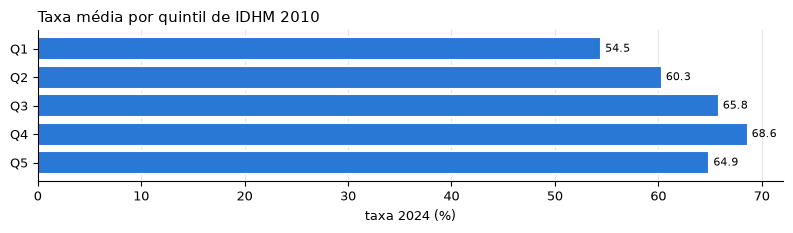

In [64]:
df_s1 = df_base.dropna(subset=["idhm", "taxa_2024"]).copy()
df_s1["quintil_idhm"] = pd.qcut(df_s1["idhm"], 5, labels=["Q1", "Q2", "Q3", "Q4", "Q5"])
print(df_s1[["idhm", "idhm_e", "renda_pc", "pib_per_capita", "expectativa_anos_estudo", "taxa_2024"]].corr(method="spearman")["taxa_2024"].round(3).to_string())
plot_barras(df_s1.groupby("quintil_idhm", observed=True, as_index=False)["taxa_2024"].mean(), "quintil_idhm", "taxa_2024", titulo="Taxa média por quintil de IDHM 2010", xlabel="taxa 2024 (%)")

**Resposta:** Sim, mas fraco (Spearman de 0,21 para IDHM, 0,16 para renda). A taxa sobe até o Q4 (68,6%) e recua no Q5 (64,9%), portanto a relação não é linear.

#### Maior vulnerabilidade social está associada a taxas menores?

prop_pobreza_criancas   -0.21
indice_gini             -0.22
taxa_2024                1.00


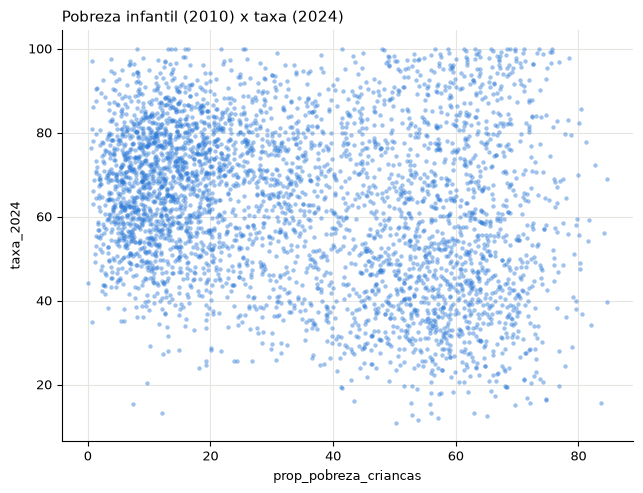

In [65]:
print(df_base[["prop_pobreza_criancas", "indice_gini", "taxa_2024"]].corr(method="spearman")["taxa_2024"].round(3).to_string())
plot_dispersao(df_base[df_base["n_2024"] >= par_min_alunos], "prop_pobreza_criancas", "taxa_2024", titulo="Pobreza infantil (2010) x taxa (2024)")

**Resposta:** Sim, fraco (-0,21 para pobreza infantil, -0,22 para Gini). Os dados são de 2010, e a nuvem é muito dispersa.

#### Melhor infraestrutura escolar está associada a taxas maiores?

In [66]:
par_infra = ["pct_biblioteca", "pct_internet_alunos", "pct_esgoto_rede"]
pd.DataFrame({"correlacao": [df_base[v].corr(df_base["taxa_2024"], method="spearman") for v in par_infra],
              "parcial_controlando_idhm": [correlacao_parcial(df_base, v, "taxa_2024", ["idhm"]) for v in par_infra]}, index=par_infra)

,correlacao,parcial_controlando_idhm
pct_biblioteca,0.25,0.17
pct_internet_alunos,0.06,-0.02
pct_esgoto_rede,0.13,0.04


**Resposta:** Só para biblioteca, e fraco (0,25; parcial de 0,17). Internet e esgoto quase desaparecem ao controlar por IDHM.

#### Docentes, turmas e fluxo escolar influenciam o resultado?

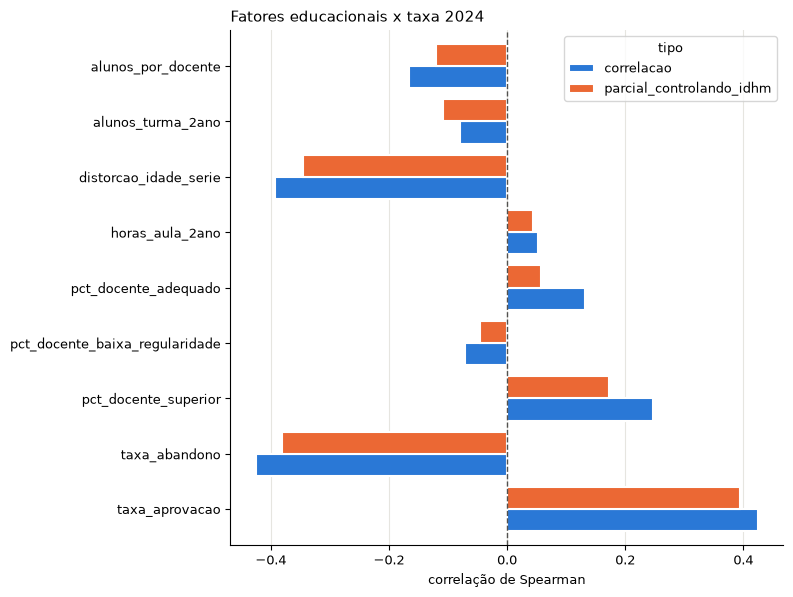

In [67]:
par_escola = ["pct_docente_superior", "pct_docente_adequado", "pct_docente_baixa_regularidade", "alunos_turma_2ano", "alunos_por_docente",
              "horas_aula_2ano", "distorcao_idade_serie", "taxa_aprovacao", "taxa_abandono"]
df_s4 = pd.DataFrame({"correlacao": [df_base[v].corr(df_base["taxa_2024"], method="spearman") for v in par_escola],
                      "parcial_controlando_idhm": [correlacao_parcial(df_base, v, "taxa_2024", ["idhm"]) for v in par_escola]}, index=par_escola)
plot_barras(df_s4.reset_index().melt("index", var_name="tipo", value_name="spearman"), "index", "spearman", hue="tipo",
            titulo="Fatores educacionais x taxa 2024", xlabel="correlação de Spearman", referencia=0)

**Resposta:** O fluxo escolar é o sinal mais forte (aprovação 0,42; abandono -0,43; distorção -0,39) e resiste ao IDHM. Docente com formação superior vem depois. Aprovação e abandono podem refletir o próprio desempenho, mesmo sendo de 2022.

#### O investimento por aluno tem efeito após controlar pela renda?

In [68]:
par_invest = ["invest_aluno_fundamental", "despesa_professor_aluno"]
pd.DataFrame({"correlacao": [df_base[v].corr(df_base["taxa_2024"], method="spearman") for v in par_invest],
              "parcial_renda": [correlacao_parcial(df_base, v, "taxa_2024", ["renda_pc"]) for v in par_invest],
              "parcial_renda_e_regiao": [correlacao_parcial(df_base.assign(regiao_cod=df_base["nome_regiao"].map(df_base.groupby("nome_regiao")["taxa_2024"].mean())), v, "taxa_2024", ["renda_pc", "regiao_cod"]) for v in par_invest]}, index=par_invest)

,correlacao,parcial_renda,parcial_renda_e_regiao
invest_aluno_fundamental,0.20,0.16,0.10
despesa_professor_aluno,-0.05,-0.04,-0.02


**Resposta:** O efeito é pequeno (0,20; 0,10 após renda e região), e a despesa com professores não mostra associação. É correlação, não impacto causal.

#### Porte e ruralidade modificam as relações anteriores?

In [69]:
df_s6 = df_base.copy()
df_s6["faixa_populacao"] = pd.cut(df_s6["populacao"], [0, 10_000, 50_000, 200_000, np.inf], labels=["<10 mil", "10-50 mil", "50-200 mil", "200 mil+"])
df_s6["faixa_rural"] = pd.cut(df_s6["pct_escolas_rurais"], [-1, 25, 50, 75, 100], labels=["0-25%", "25-50%", "50-75%", "75-100%"])
pd.concat({f: df_s6.groupby(f, observed=True).apply(lambda d: pd.Series({"municipios": len(d), "taxa_media": d["taxa_2024"].mean(),
                                                                          "corr_idhm": d["idhm"].corr(d["taxa_2024"], method="spearman"),
                                                                          "corr_docente": d["pct_docente_adequado"].corr(d["taxa_2024"], method="spearman")}))
           for f in ["faixa_populacao", "faixa_rural"]})

municipios  taxa_media  corr_idhm  corr_docente
faixa_populacao <10 mil       2,444.00       66.19       0.20          0.09
                10-50 mil     2,401.00       60.75       0.30          0.15
                50-200 mil      505.00       58.61       0.28          0.24
                200 mil+        150.00       55.08       0.21          0.13
faixa_rural     0-25%         1,918.00       67.69      -0.13          0.00
                25-50%        1,137.00       63.90       0.12          0.11
                50-75%        1,161.00       61.38       0.16          0.09
                75-100%       1,284.00       55.70       0.15          0.03

**Resposta:** Sim: a taxa é maior em municípios pequenos e com poucas escolas rurais. A relação com IDHM até se inverte (-0,13) onde há menos escolas rurais, o que justifica modelos não lineares.

### 12. Correlações e seleção de variáveis

#### Quais variáveis têm maior associação com o alvo?

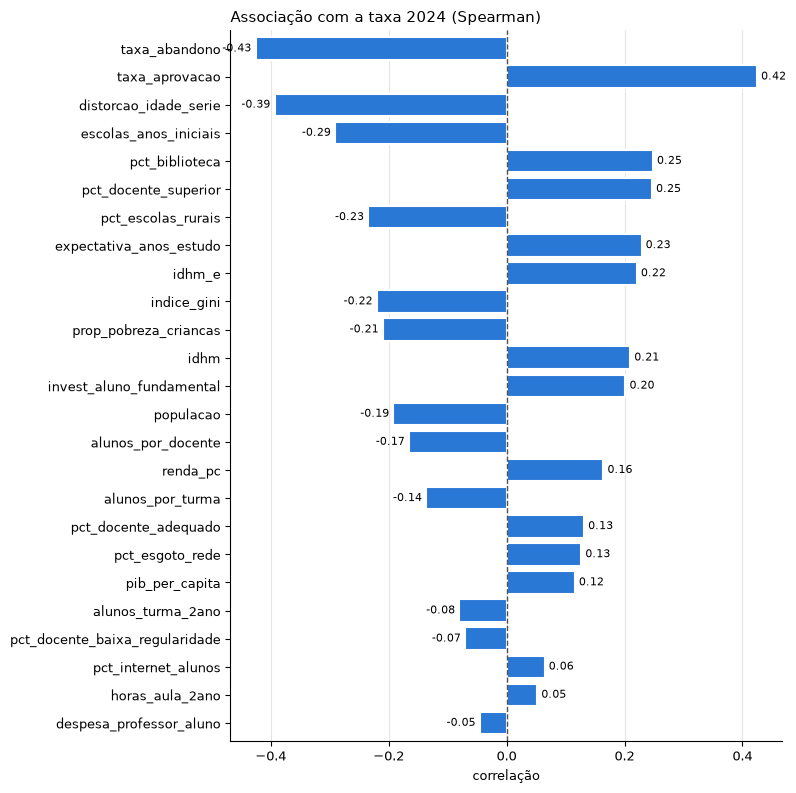

In [70]:
df_c1 = df_base[par_variaveis].corrwith(df_base["taxa_2024"], method="spearman").rename("spearman").reset_index()
df_c1 = df_c1.assign(abs=df_c1["spearman"].abs()).sort_values("abs", ascending=False)
plot_barras(df_c1, "index", "spearman", titulo="Associação com a taxa 2024 (Spearman)", xlabel="correlação", referencia=0, fmt="%.2f")

In [71]:
df_c1_cat = df_painel.dropna(subset=["atingiu_meta_ano"])
pd.Series({v: v_cramer(df_c1_cat[v], df_c1_cat["atingiu_meta_ano"].astype(bool)) for v in ["nome_regiao", "sigla_uf", "porte"]}, name="v_cramer_atingiu_meta").to_frame()

,v_cramer_atingiu_meta
nome_regiao,0.26
sigla_uf,0.44
porte,0.07


In [72]:
from sklearn.feature_selection import mutual_info_regression

df_mi = df_base.dropna(subset=["taxa_2024"])
X_mi = df_mi[par_variaveis].astype(float)
X_mi = X_mi.fillna(X_mi.median())
df_c1_mi = pd.DataFrame({"informacao_mutua": mutual_info_regression(X_mi, df_mi["taxa_2024"].astype(float), random_state=par_seed)}, index=par_variaveis)
df_c1_mi["spearman"] = df_c1.set_index("index")["spearman"].reindex(df_c1_mi.index)
df_c1_mi.sort_values("informacao_mutua", ascending=False).head(12)

,informacao_mutua,spearman
taxa_aprovacao,0.13,0.42
taxa_abandono,0.13,-0.43
prop_pobreza_criancas,0.08,-0.21
renda_pc,0.08,0.16
idhm_e,0.07,0.22
distorcao_idade_serie,0.07,-0.39
idhm,0.07,0.21
pct_docente_superior,0.07,0.25
pct_biblioteca,0.06,0.25
escolas_anos_iniciais,0.06,-0.29


**Resposta:** As mais associadas são abandono, aprovação e distorção idade-série (cerca de 0,4 em módulo). Entre categóricas, UF (V = 0,44) supera região (0,26) e porte (0,07) para explicar o alcance da meta. A informação mútua, que capta relações não lineares, confirma aprovação e abandono no topo (0,13) e sobe pobreza infantil e renda (0,08), que têm Spearman fraco (-0,21 e 0,16). Isso reforça a não linearidade vista na relação com IDHM e renda (seção 11) e nos limiares da seção 12.

#### Quais variáveis são redundantes entre si?

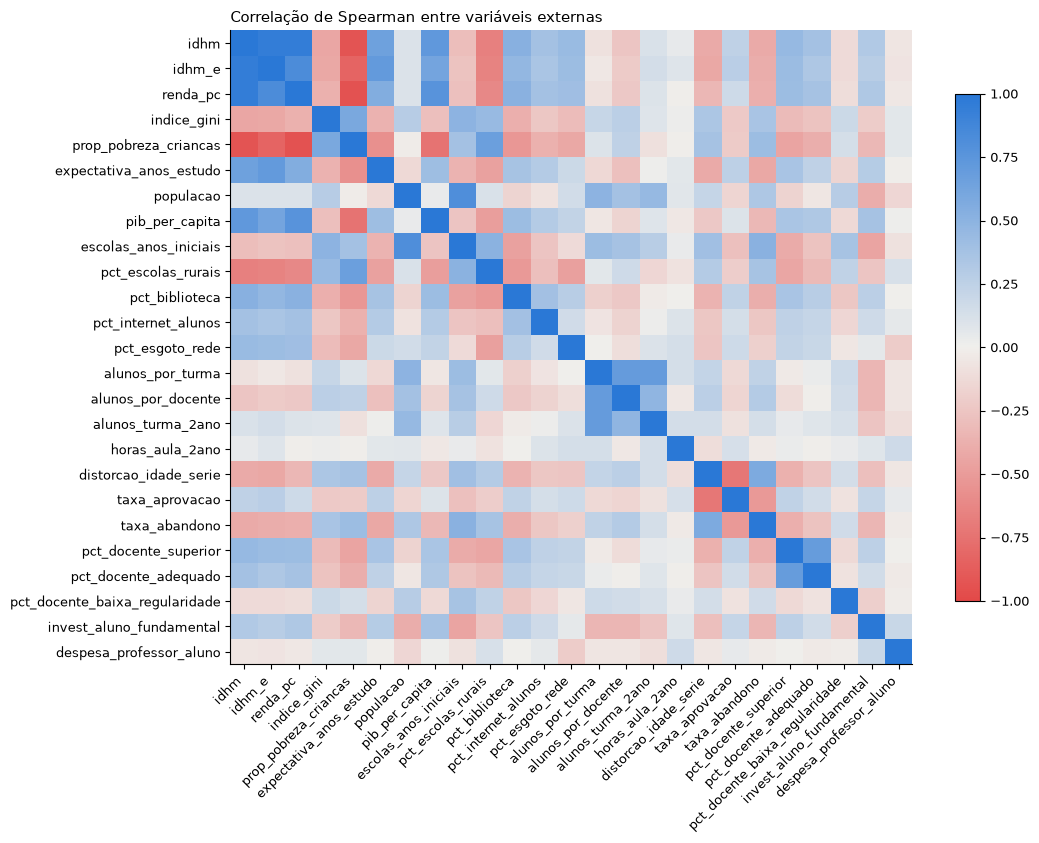

In [73]:
df_c2 = df_base[par_variaveis].corr(method="spearman")
plot_heatmap(df_c2, titulo="Correlação de Spearman entre variáveis externas", divergente=True, fmt=".1f", figsize=(11, 8.5))

In [74]:
df_c2_pares = df_c2.where(np.triu(np.ones(df_c2.shape, dtype=bool), 1)).stack().rename("spearman").reset_index()
df_c2_pares[df_c2_pares["spearman"].abs() >= .7].sort_values("spearman", key=abs, ascending=False)

,level_0,level_1,spearman
1,idhm,idhm_e,0.95
2,idhm,renda_pc,0.95
54,renda_pc,prop_pobreza_criancas,-0.94
4,idhm,prop_pobreza_criancas,-0.92
29,idhm_e,prop_pobreza_criancas,-0.83
27,idhm_e,renda_pc,0.83
158,populacao,escolas_anos_iniciais,0.81
57,renda_pc,pib_per_capita,0.77
107,prop_pobreza_criancas,pib_per_capita,-0.74
7,idhm,pib_per_capita,0.73


**Resposta:** IDHM, renda, IDHM-E e pobreza infantil são redundantes (|r| de 0,83 a 0,95). Manter uma ou duas para estabilizar o SHAP. População e nº de escolas também (0,81).

#### As relações são lineares ou têm limiares?

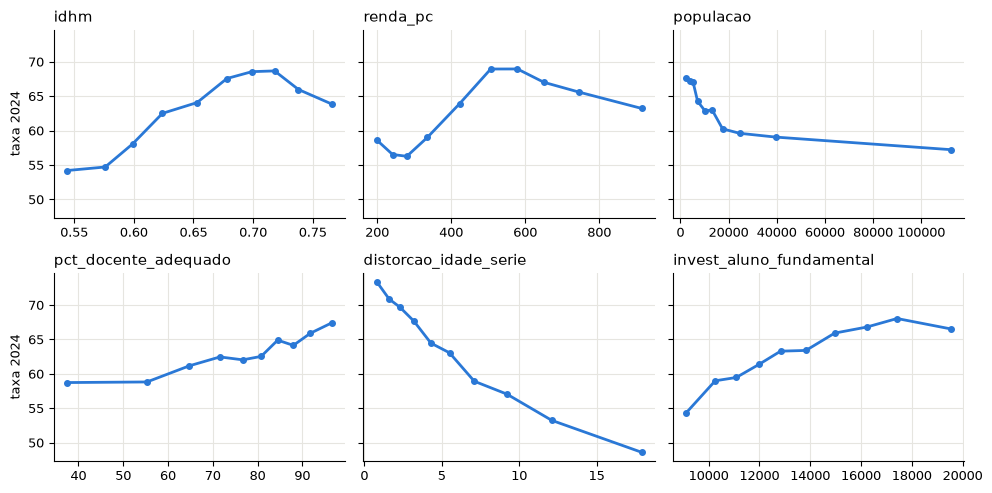

In [75]:
par_c3 = ["idhm", "renda_pc", "populacao", "pct_docente_adequado", "distorcao_idade_serie", "invest_aluno_fundamental"]
fig, eixos = plt.subplots(2, 3, figsize=(10, 5), sharey=True)
for ax, v in zip(eixos.flat, par_c3):
    decis = df_base.groupby(pd.qcut(df_base[v], 10, duplicates="drop"), observed=True).agg(x=(v, "median"), y=("taxa_2024", "mean"))
    ax.plot(decis["x"], decis["y"], color=par_cores[0], linewidth=2, marker="o", markersize=4)
    ax.set_title(v)
eixos[0, 0].set_ylabel("taxa 2024")
eixos[1, 0].set_ylabel("taxa 2024")
plt.tight_layout()
plt.show()

**Resposta:** Há não linearidades: IDHM e renda têm pico e recuo, e população cai rápido nas menores faixas. Favorece modelos de árvore ou transformações.

#### Quais variáveis têm valores faltantes e com qual padrão?

In [76]:
df_c4 = resumo_colunas(df_base[par_variaveis]).sort_values("pct_nulos", ascending=False)
df_c4[["pct_nulos"]].T

,alunos_turma_2ano,pct_docente_adequado,horas_aula_2ano,idhm_e,prop_pobreza_criancas,expectativa_anos_estudo,renda_pc,indice_gini,idhm,taxa_aprovacao,taxa_abandono,pct_docente_superior,distorcao_idade_serie,despesa_professor_aluno,invest_aluno_fundamental,alunos_por_docente,alunos_por_turma,pct_docente_baixa_regularidade,escolas_anos_iniciais,populacao,pib_per_capita,pct_escolas_rurais,pct_biblioteca,pct_internet_alunos,pct_esgoto_rede
pct_nulos,0.33,0.22,0.15,0.09,0.09,0.09,0.09,0.09,0.09,0.09,0.09,0.09,0.09,0.04,0.04,0.02,0.02,0.02,0.00,0.00,0.00,0.00,0.00,0.00,0.00


In [77]:
df_c4_regiao = df_base.groupby("nome_regiao")[par_variaveis].apply(lambda d: d.isna().mean() * 100).T
df_c4_regiao[df_c4_regiao.max(axis=1) > 1]

nome_regiao,Centro-Oeste,Nordeste,Norte,Sudeste,Sul
alunos_turma_2ano,1.29,0.00,0.46,0.24,0.51


In [78]:
df_c4_taxa = df_base[df_base[par_variaveis].isna().any(axis=1)]
print("Municípios com algum nulo:", len(df_c4_taxa), "| taxa média:", round(df_c4_taxa["taxa_2024"].mean(), 1), "| demais:", round(df_base.drop(df_c4_taxa.index)["taxa_2024"].mean(), 1))

Municípios com algum nulo: 33 | taxa média: 58.1 | demais: 62.8


**Resposta:** Os nulos são raros (até 0,33%), somando 33 municípios. Imputação simples com indicador de ausência é suficiente, ajustada só no treino.

### 13. Vazamento de dados

#### Quais colunas derivam diretamente do alvo?

In [79]:
pd.DataFrame([{"erros_acima_corte": ((df_scr_aluno["proficiencia"] >= par_corte) & ~df_scr_aluno["alfabetizado"]).sum(),
               "erros_abaixo_corte": ((df_scr_aluno["proficiencia"] < par_corte) & df_scr_aluno["alfabetizado"]).sum(),
               "corr_proficiencia_alvo": df_scr_aluno["proficiencia"].corr(df_scr_aluno["alfabetizado_id"].astype(float))}])

,erros_acima_corte,erros_abaixo_corte,corr_proficiencia_alvo
0,0,0,0.80


In [80]:
df_l1 = df_scr_indicador_municipio[df_scr_indicador_municipio["ano"] == 2024]
df_l1[["media_portugues", "proporcao_aluno_nivel_0", "proporcao_aluno_nivel_4", "proporcao_aluno_nivel_8"]].corrwith(df_l1["taxa_alfabetizacao"], method="spearman").rename("spearman_com_taxa").to_frame()

,spearman_com_taxa
media_portugues,0.96
proporcao_aluno_nivel_0,-0.59
proporcao_aluno_nivel_4,-0.58
proporcao_aluno_nivel_8,0.58


**Resposta:** `proficiencia` define o alvo sem nenhuma exceção. `media_portugues` (0,96) e as proporções por nível também derivam dele. Excluir todas no mesmo ano.

#### Quais colunas só existem depois da prova?

In [81]:
(df_scr_aluno.assign(peso_nulo=df_scr_aluno["peso_aluno"].isna(), proficiencia_nula=df_scr_aluno["proficiencia"].isna())
 .groupby(["presenca", "preenchimento_caderno", "peso_nulo", "proficiencia_nula", "alfabetizado"], dropna=False).size()
 .rename("alunos").sort_values(ascending=False).reset_index())

,presenca,preenchimento_caderno,peso_nulo,proficiencia_nula,alfabetizado,alunos
0,True,True,False,False,True,1984546
1,True,True,False,False,False,1370115
2,False,False,True,True,False,512153
3,True,False,True,True,False,1185


**Resposta:** `presenca`, `preenchimento_caderno` e `peso_aluno` só existem após a prova, e os nulos de peso coincidem com os não avaliados. Excluir.

#### No alvo municipal, quais colunas revelam a resposta?

In [82]:
df_l3 = df_painel.dropna(subset=["atingiu_meta_ano"]).merge(df_municipal.query("ano == 2024")[["id_municipio", "gap_meta_ano"]], on="id_municipio")
pd.crosstab(df_l3["gap_meta_ano"] >= 0, df_l3["atingiu_meta_ano"].astype(bool))

atingiu_meta_ano,False,True
gap_meta_ano,,
False,2444,0
True,0,2788


In [83]:
print("Soma gap_ate_2030 + taxa = meta_2030:", ((df_l3["gap_ate_2030"] + df_l3["taxa_2024"] - df_l3["meta_2030"]).abs() < .02).mean())

Soma gap_ate_2030 + taxa = meta_2030: 1.0


**Resposta:** `gap_meta_ano` determina o alvo por completo, e `gap_ate_2030` revela a taxa. Excluir no mesmo ano; a meta em si pode ficar.

#### Médias por escola ou município incluem o próprio aluno?

In [84]:
df_l4_base = (df_scr_aluno[(df_scr_aluno["ano"] == 2024) & df_scr_aluno["proficiencia"].notna()
                           & df_scr_aluno["rede_id"].isin([par_rede_estadual, par_rede_municipal])]
              [["id_aluno", "id_escola", "alfabetizado_id"]].rename(columns={"alfabetizado_id": "y"}))
df_l4_base["teste"] = amostra_hash(df_l4_base["id_aluno"])
com_proprio = df_l4_base.groupby("id_escola")["y"].agg(taxa_com_proprio="mean", n="size")
so_treino = df_l4_base[~df_l4_base["teste"]].groupby("id_escola")["y"].mean().rename("taxa_treino")
df_l4 = (df_l4_base[df_l4_base["teste"] & amostra_hash(df_l4_base["id_aluno"] + "a")]
         .join(com_proprio, on="id_escola").join(so_treino, on="id_escola")[["y", "taxa_com_proprio", "taxa_treino", "n"]])
df_l4_ok = df_l4.dropna()
print("AUC, média da escola com o próprio aluno:", round(auc(df_l4_ok["y"], df_l4_ok["taxa_com_proprio"]), 4))
print("AUC, média da escola só com o treino:", round(auc(df_l4_ok["y"], df_l4_ok["taxa_treino"]), 4))

AUC, média da escola com o próprio aluno: 0.739
AUC, média da escola só com o treino: 0.7095


In [85]:
df_l4_ok = df_l4_ok.assign(faixa_n=pd.cut(df_l4_ok["n"], [0, 10, 20, 40, 1000]))
df_l4_ok.groupby("faixa_n", observed=True).apply(lambda d: pd.Series({"alunos": len(d), "auc_com_proprio": auc(d["y"], d["taxa_com_proprio"]), "auc_so_treino": auc(d["y"], d["taxa_treino"])}))

,alunos,auc_com_proprio,auc_so_treino
faixa_n,,,
"(0, 10]",733.00,0.85,0.75
"(10, 20]","5,936.00",0.81,0.75
"(20, 40]","14,618.00",0.77,0.73
"(40, 1000]","52,845.00",0.72,0.70


**Resposta:** Sim, se calculadas sem cuidado: a AUC sobe de 0,710 para 0,739, com efeito maior em escolas pequenas (0,75 para 0,85). Calcular dentro de cada dobra.

#### Alunos da mesma escola podem cair em treino e teste?

In [86]:
df_l5_base = (df_scr_aluno[df_scr_aluno["proficiencia"].notna() & df_scr_aluno["rede_id"].isin([par_rede_estadual, par_rede_municipal])]
              [["ano", "id_aluno", "id_escola", "id_municipio", "alfabetizado_id"]].rename(columns={"alfabetizado_id": "y"})
              .merge(df_scr_municipio[["id_municipio", "sigla_uf"]], on="id_municipio"))
for chave in ["aluno", "escola", "municipio"]:
    df_l5_base[f"teste_{chave}"] = amostra_hash(df_l5_base[f"id_{chave}"])
b24 = df_l5_base[df_l5_base["ano"] == 2024]


def cenario(nome, treino, chave, teste=None):
    score = treino.groupby(chave)["y"].mean().rename("score")
    alvo = b24 if teste is None else b24[b24[teste]]
    return alvo.join(score, on=chave, how="inner")[["y", "score"]].assign(cenario=nome)


df_l5 = pd.concat([cenario("Aleatória por aluno: média da escola", b24[~b24["teste_aluno"]], "id_escola", "teste_aluno"),
                   cenario("Aleatória por aluno: média do município", b24[~b24["teste_aluno"]], "id_municipio", "teste_aluno"),
                   cenario("Por escola: média do município", b24[~b24["teste_escola"]], "id_municipio", "teste_escola"),
                   cenario("Por município: média da UF", b24[~b24["teste_municipio"]], "sigla_uf", "teste_municipio"),
                   cenario("Temporal 2023 > 2024: média do município", df_l5_base[df_l5_base["ano"] == 2023], "id_municipio")])
df_l5_res = df_l5.groupby("cenario").apply(lambda d: pd.Series({"alunos_teste": len(d), "auc": auc(d["y"], d["score"])})).sort_values("auc", ascending=False).reset_index()
df_l5_res

,cenario,alunos_teste,auc
0,Aleatória por aluno: média da escola,"370,355.00",0.71
1,Aleatória por aluno: média do município,"370,355.00",0.67
2,Por escola: média do município,"358,078.00",0.66
3,Temporal 2023 > 2024: média do município,"1,423,709.00",0.65
4,Por município: média da UF,"442,572.00",0.62


**Resposta:** Sim, e isso infla o resultado: a AUC cai de 0,71 (aluno) para 0,66 (escola nova), 0,65 (temporal) e 0,62 (município novo). Separar por grupo. Esses valores servem de referência a superar.

### 14. Equidade

#### O erro pode variar entre regiões, redes e portes?

In [87]:
df_j1 = df_mun_aluno[df_mun_aluno["rede_id"].isin(["2", "3"])].pivot(index=["id_municipio", "rede_id", "nome_regiao"], columns="ano", values="taxa_ponderada").dropna().reset_index()
df_j1 = df_j1.merge(df_mun_aluno.query("ano == 2024")[["id_municipio", "rede_id", "porte"]], on=["id_municipio", "rede_id"])
df_j1["erro_abs"] = (df_j1[2024] - df_j1[2023]).abs()
pd.concat({c: df_j1.groupby(c, observed=True)["erro_abs"].agg(municipios="size", erro_medio="mean") for c in ["nome_regiao", "rede_id", "porte"]})

municipios  erro_medio
nome_regiao Centro-Oeste         496       12.62
            Nordeste            1916       12.01
            Norte                492       10.99
            Sudeste             1262       14.91
            Sul                 1549       14.92
rede_id     2                    940       16.15
            3                   4775       12.86
porte       <30                  903       21.21
            30-99               2155       14.68
            100-299             1698       10.78
            300-999              730        8.38
            1000+                229        6.08

**Resposta:** Sim, em um baseline que repete a taxa de 2023: o erro vai de 6,1 pontos (1000+) a 21,2 (<30), e é maior no Sul e Sudeste que no Norte. Por isso os modelos são avaliados por região, rede e porte.

#### Municípios com poucos dados podem receber classificações instáveis?

In [88]:
df_j2 = df_painel.dropna(subset=["taxa_2023", "taxa_2024", "porte"]).copy()
df_j2["risco_2023"] = df_j2["taxa_2023"] <= df_j2["taxa_2023"].quantile(.2)
df_j2["risco_2024"] = df_j2["taxa_2024"] <= df_j2["taxa_2024"].quantile(.2)
df_j2[df_j2["risco_2023"]].groupby("porte", observed=True).agg(em_risco_2023=("risco_2023", "size"), pct_segue_em_risco=("risco_2024", lambda s: 100 * s.mean()))

,em_risco_2023,pct_segue_em_risco
porte,,
<30,103,33.98
30-99,400,53.50
100-299,368,65.76
300-999,163,75.46
1000+,46,71.74


**Resposta:** Sim: entre os de maior risco em 2023, só 34,0% dos menores seguem nessa faixa em 2024, contra cerca de 72% a 75% nos maiores. Mostrar faixa de confiança e não classificar municípios muito pequenos sem ressalva.

#### Território como variável pode reproduzir desigualdades?

                modelo   r2
0                Só UF 0.53
1    Só socioeconômico 0.08
2  UF + socioeconômico 0.53


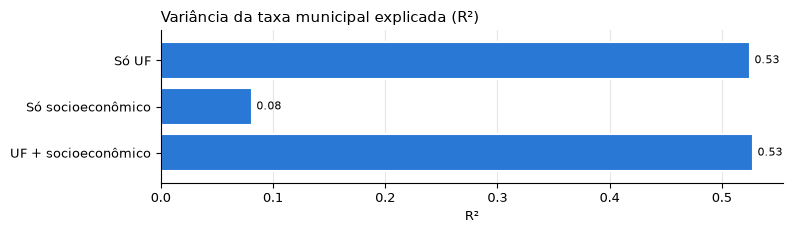

In [89]:
df_j3 = df_base.dropna(subset=["taxa_2024", "idhm", "renda_pc", "prop_pobreza_criancas"]).query("n_2024 >= @par_min_alunos")
X_uf = pd.get_dummies(df_j3["sigla_uf"], drop_first=True).astype(float)
X_soc = df_j3[["idhm", "renda_pc", "prop_pobreza_criancas"]]
df_j3_res = pd.DataFrame({"modelo": ["Só UF", "Só socioeconômico", "UF + socioeconômico"],
                          "r2": [r2_ols(X_uf, df_j3["taxa_2024"]), r2_ols(X_soc, df_j3["taxa_2024"]), r2_ols(pd.concat([X_uf, X_soc], axis=1), df_j3["taxa_2024"])]})
print(df_j3_res.round(3).to_string())
plot_barras(df_j3_res, "modelo", "r2", titulo="Variância da taxa municipal explicada (R²)", xlabel="R²", fmt="%.2f")

**Resposta:** Sim: UF explica 53% da variação municipal e o socioeconômico, 8%, com quase nada de ganho ao somar. UF pode mascarar políticas estaduais ou diferenças de medição; comparar modelos com e sem UF e documentar.